# 나이·BMI·흡연 여부로 개인의 의료비를 얼마나 설명할 수 있는가

## 1. 분석 개요

### 분석 주제

공개 데이터인 Insurance 데이터셋을 이용해 **개인의 특성이 의료비와 어떤 관련이 있으며, 의료비 차이를 얼마나 설명할 수 있는지** 확인한다. 나이·BMI·흡연 여부를 중심으로 데이터를 살펴보고, 선형회귀의 전체 과정인 품질 점검 → 탐색적 분석 → 모델링 → 진단 → 해석을 연습한다.

이 분석에서 `charges`는 보험사가 청구한 개인별 의료비를 뜻하며, 가입자가 정기적으로 납부하는 보험료와는 구분한다.

### 분석 질문

- **Q1.** 나이·BMI·흡연 여부를 비롯한 개인 특성 중 의료비와 가장 뚜렷한 관련이 있는 요인은 무엇인가?
- **Q2.** 나이와 BMI가 같아도 흡연 여부에 따라 의료비 차이가 나타나는가? BMI와 의료비의 관계는 흡연자와 비흡연자에게서 다르게 나타나는가?
- **Q3.** 기본 선형회귀와 의료비의 로그 변환·나이의 제곱항·BMI와 흡연 여부의 상호작용을 반영한 모형을 비교했을 때, 어떤 모형이 의료비를 더 잘 설명하고 예측하는가?

**종속변수:** `charges` — 개인별 의료비(연속형, 달러 단위) → 회귀 문제

**설명변수:** `age`, `sex`, `bmi`, `children`, `smoker`, `region`

### 이번 노트북에서 연습할 기법 — 선형회귀

데이터의 구조와 품질을 점검하고, 탐색적 분석을 통해 각 변수의 분포와 변수 간 관계를 확인한다. 이후 여러 설명변수를 함께 사용하는 다중선형회귀를 적용하여 다른 조건이 같을 때 각 개인 특성이 의료비와 어떤 관계를 보이는지 살펴본다.

구체적인 자료형 변환, 변수 변환 및 모형 구성 방법은 데이터의 실제 분포와 탐색적 분석 결과를 확인한 뒤 결정한다.

#### 1-1. 분석 환경 설정

> 분석에 필요한 개별 함수 **import**

In [1]:
import sys

portfolio_path = r"C:\Data-Analysis-Portfolio"

if portfolio_path not in sys.path:
    sys.path.insert(0, portfolio_path)

from jihyelab import upload_data

In [2]:
from helpers import *
from IPython.display import display, Markdown

import pandas as pd
import numpy as np
import statsmodels.api as sm

---
## #2. 데이터 소개

#### 2-1. 데이터 로딩

In [3]:
# 캐글데이터 주소 모음집
data = upload_data(
    "insurance",
    local=r"C:\Data-Analysis-Portfolio\dataset_repository",
)

data.head()

📚 개인의 나이·성별·BMI·자녀 수·흡연 여부·거주 지역을 바탕으로 의료보험 청구 비용을 분석하고 예측하는 데이터셋 (출처: https://www.kaggle.com/datasets/mirichoi0218/insurance)

    field     description
--  --------  --------------------------------------------------------------
 0  age       보험 가입자의 나이
 1  sex       보험 가입자의 성별 (male, female)
 2  bmi       체질량지수(Body Mass Index)
 3  children  보험에 등록된 부양 자녀 수
 4  smoker    흡연 여부 (yes, no)
 5  region    미국 내 거주 지역 (northeast, northwest, southeast, southwest)
 6  charges   개인별 의료보험 청구 비용



,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


#### 문자열 공백 제거
- 문자열형 변수의 앞뒤 불필요한 공백을 제거해, 같은 값이 공백 때문에 서로 다른 범주로 인식되는 오류를 방지하기 위해 사용한다.

In [5]:
for col in data.select_dtypes(include=['object', 'category']).columns:
    data[col] = data[col].astype(str).str.strip()

#### 2-2. 출처와 분석 단위

- **출처:** Medical Cost Personal Datasets — Kaggle 배포본 [`mirichoi0218/insurance`](https://www.kaggle.com/datasets/mirichoi0218/insurance), Brett Lantz의 『Machine Learning with R』에서 사용한 데이터
- **수집 기간:** 배포 자료에 구체적인 수집 연도와 기간이 명시되어 있지 않음
- **분석 단위:** 1행 = 개인 1명의 특성(나이·성별·BMI·자녀 수·흡연 여부·거주 지역)과 해당 개인의 의료비(`charges`) 기록

#### 2-3. 변수 정의서

| 변수명 | 의미 | 역할 | 척도 | 단위 |
|---|---|---|---|---|
| `charges` | 개인별 의료보험 청구 비용 | 종속변수 | 연속형 | 달러($) |
| `age` | 보험 가입자의 나이 | 독립변수 | 정량형(정수 기록) | 세 |
| `sex` | 보험 가입자의 성별 | 독립변수 | 명목형(2집단) | male=남성 / female=여성 |
| `bmi` | 체질량지수(체중 ÷ 키²) | 독립변수 | 연속형 | kg/m² |
| `children` | 보험에 등록된 부양 자녀 수 | 독립변수 | 이산형 | 명 |
| `smoker` | 흡연 여부 | 독립변수 | 명목형(2집단) | yes=흡연 / no=비흡연 |
| `region` | 미국 내 거주 지역 | 독립변수 | 명목형(4집단) | northeast=북동부 / northwest=북서부 / southeast=남동부 / southwest=남서부 |

※ 전체 1,338행, 7개 변수이며, 모든 변수에서 결측값이 없다. `age`는 정수로 기록되어 있지만, 이번 선형회귀에서는 연속적인 수치 변수로 취급한다. `sex`, `smoker`, `region`은 더미 변수로 변환해 모형에 투입한다.

#### 2-4. 초기 가설

- **H1. 흡연자는 비흡연자보다 의료비가 높을 것이다.** 
- **H2. 나이가 많을수록 의료비가 높아지며, 증가 폭은 일정하지 않을 수 있다.** 
- **H3. BMI가 높을수록 의료비가 높아지는 경향은 흡연자에게서 더 뚜렷할 것이다.** 
- **H4. 거주 지역에 따라 의료 보험비 수준에 유의한 차이가 있을 것이다.**

위 가설은 분석 전의 예상이며, 실제 데이터와 모형 진단 결과에 따라 기각하거나 수정한다.

#### 2-5. 데이터의 한계

- **인과관계를 확인할 수 없다.** 관찰된 개인 특성과 의료비의 관련성을 분석하는 자료이므로, 특정 특성이 의료비 증가를 직접 유발한다고 단정할 수 없다.
- **의료비에 영향을 주는 중요한 정보가 빠져 있다.** 기존 질환, 진료 내용, 의료 이용 횟수, 보험 보장 범위 등의 정보가 없어 개인별 의료비 차이를 완전히 설명하기 어렵다.
- **다른 집단에 그대로 적용하기 어렵다.** 자료의 수집 방식과 대표성을 충분히 확인하지 못한 상태에서는 결과를 전체 인구나 한국의 의료·보험 환경으로 일반화할 수 없다.
- **한 사람의 의료비가 시간에 따라 어떻게 변하는지는 알 수 없다.** 개인별 추적 자료가 아니므로 노화나 금연 전후의 의료비 변화를 직접 분석할 수 없다.
- **높은 의료비 관측값이 결과에 큰 영향을 줄 수 있다.** 높은 값이라는 이유만으로 제거하지 않고, 데이터 오류 여부와 모형에 미치는 영향을 확인해야 한다.
- **실제 보험료 산정에 사용하는 모형은 아니다.** 이 노트북은 의료비의 관련 요인을 이해하고 선형회귀를 연습하기 위한 분석이며, 개인의 보험료나 가입 가능 여부를 결정하는 근거로 사용하지 않는다.

---
## #3. 품질 점검 및 기본 전처리

> 이 장에서는 **삭제만** 수행한다. 결측치·이상치의 **대체는 #6**의 전처리 파이프라인에서 한다.
> 전처리 기준이 분석 설계보다 앞서면 판단 근거가 사라지기 때문이다.

#### 3-1. 데이터 구조 점검

##### 1) 자료형 확인

In [6]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


##### 2) 자료형 확인 및 변환

- `smoker`(흡연 여부)는 두 범주로 구성된 **명목형 변수**이다. 분석 및 모델링에 활용할 수 있도록 `yes=1`, `no=0`으로 매핑하여 **이진형 정수 변수(`int64`)로 변환하였다.**
- `sex`(성별)는 두 범주로 구성된 **명목형 변수**이다. 분석 및 모델링에 활용할 수 있도록 `male=1`, `female=0`으로 매핑하여 **이진형 정수 변수(`int64`)로 변환하였다.**
- `region`(거주 지역)은 순서가 없는 여러 범주로 구성된 **명목형 변수**이다. 범주형 변수임을 명확하게 지정하기 위해 `category` 자료형으로 변환하였다.
- 그 외 변수는 기존 자료형을 유지하였다.
  - `age`, `children`: 정수형(`int64`)
  - `bmi`, `charges`: 실수형(`float64`)

※ `sex`와 `smoker`에서 사용된 `0`과 `1`은 **각 범주를 구분하기 위한 값으로, 크기·순서·우열을 의미하지 않는다.**

※ 현재 단계에서는 `region`에 대한 **원-핫 인코딩을 수행하지 않았으며**, 범주형(`category`)으로만 지정하였다. 필요할 경우 이후 모델링 단계에서 더미 변수로 변환할 수 있다.

In [7]:
# 두 범주를 0과 1로 변환
data["smoker"] = data["smoker"].map({"yes": 1, "no": 0})
data["sex"] = data["sex"].map({"male": 1, "female": 0})

# region 컬럼을 category 타입으로 변환
df1 = my_qtcheck.set_type(data, as_category=['sex', 'smoker', 'region'])

df1.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       1338 non-null   int64   
 1   sex       1338 non-null   category
 2   bmi       1338 non-null   float64 
 3   children  1338 non-null   int64   
 4   smoker    1338 non-null   category
 5   region    1338 non-null   category
 6   charges   1338 non-null   float64 
dtypes: category(3), float64(2), int64(2)
memory usage: 46.3 KB


,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520


##### 3) 중복 검사 및 중복 데이터 삭제

In [8]:
df2 = my_qtcheck.check_duplicates(df1)
df2.head()

중복된 행의 수: 1
중복된 행이 제거되었습니다.


,age,sex,bmi,children,smoker,region,charges
0,19,0,27.900,0,1,southwest,16884.92400
1,18,1,33.770,1,0,southeast,1725.55230
2,28,1,33.000,3,0,southeast,4449.46200
3,33,1,22.705,0,0,northwest,21984.47061
4,32,1,28.880,0,0,northwest,3866.85520


### 해석

- **자료형:** `sex`와 `smoker`는 두 범주로 구성된 명목형 변수이므로 각각 `0`과 `1`로 이진 변환한 뒤 `category` 자료형으로 지정하였다. `region` 역시 순서가 없는 명목형 변수이므로 `category` 자료형으로 변환하였다. 현재 단계에서는 `region`에 원-핫 인코딩을 적용하지 않았으며, 이후 모델링 전처리 단계에서 더미 변수로 변환할 예정이다.
- **중복 행:** **1건** — 중복된 행을 확인한 후 삭제하였다.
- **불필요한 열:** 현재 데이터는 `age`, `sex`, `bmi`, `children`, `smoker`, `region`, `charges`로 구성되어 있으며, ID나 인덱스와 같은 별도의 식별자 열이 없어 추가로 삭제할 열은 없다.
- **주의할 변수:** `sex`와 `smoker`는 값이 `0`과 `1`로 표현되지만 자료형은 범주형(`category`)이며, 숫자의 크기·순서·우열을 의미하지 않는다. `region` 역시 범주 간 순서가 없는 명목형 변수이므로 수치형 변수처럼 해석하지 않는다.
    - 품질점검 및 탐색적 분석에서는 세 변수를 범주형 변수로 구분하여 해석한다.

#### 3-2. 데이터 품질 점검

##### 1) 결측치 확인

In [9]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
age,0,0.0
sex,0,0.0
bmi,0,0.0
children,0,0.0
smoker,0,0.0
region,0,0.0
charges,0,0.0


##### 2) 이상치 확인 (IQR 기준)

`numerical_summary()` 는 기술통계량과 함께 **IQR × 1.5 경계**를 벗어난 이상치의 개수·비율을 계산한다.

In [10]:
num_desc = my_qtcheck.numerical_summary(df2)
num_desc

,count,mean,std,min,25%,50%,75%,max,rel_diff,rdiff_flag,...,upper_outliers_ratio,lower_outliers,lower_outliers_ratio,outliers,outliers_ratio,skew,skew_interpret,kurt,kurt_interpret,log_need
age,1337.0,39.222139,14.044333,18.0000,27.000,39.0000,51.00000,64.00000,0.005696,similar,...,0.000000,0,0.0,0,0.000000,0.054781,symmetric,-1.244406,platykurtic,none
bmi,1337.0,30.663452,6.100468,15.9600,26.290,30.4000,34.70000,53.13000,0.008666,similar,...,0.006731,0,0.0,9,0.006731,0.283914,symmetric,-0.052947,platykurtic,none
children,1337.0,1.095737,1.205571,0.0000,0.000,1.0000,2.00000,5.00000,0.095737,similar,...,0.000000,0,0.0,0,0.000000,0.937421,right tail,0.200954,leptokurtic,log1p
charges,1337.0,13279.121487,12110.359656,1121.8739,4746.344,9386.1613,16657.71745,63770.42801,0.414755,diff,...,0.103964,0,0.0,139,0.103964,1.515391,right tail,1.604221,leptokurtic,log


**해석**

- **결측치는 0건**으로 확인되어 별도의 결측치 처리는 하지 않았다.
- **IQR 기준 이상치는 일괄 삭제하지 않았다.**
  - `bmi`에서 **9건(약 0.7%)**, `charges`에서 **139건(약 10.4%)**의 이상치가 확인되었다.
  - 두 변수 모두 실제로 나타날 수 있는 범위의 값이며, 특히 `charges`의 높은 값은 고액 보험료 집단의 특성을 반영할 수 있어 임의로 삭제하지 않았다.
- **분포에서는 `charges`를 주의해서 볼 필요가 있다.**
  - `charges`는 왜도 약 **1.52**로 오른쪽으로 치우친 분포를 보여, 이후 선형회귀 모델링에서 로그 변환 여부를 검토한다.
  - `children`도 오른쪽 꼬리가 긴 분포지만 자녀 수를 나타내는 이산형 변수이므로 자동 로그 변환은 적용하지 않는다.
- 따라서 현재 단계에서는 원자료를 유지하고, 이후 모델링 과정에서 `charges`의 분포와 이상치가 모델에 미치는 영향을 추가로 확인한다.

#### 3-3. 기술통계량

##### 1) 연속형 변수의 기술 통계량을 전치 형태로 출력

In [11]:
num_desc.T

,age,bmi,children,charges
count,1337.0,1337.0,1337.0,1337.0
mean,39.222139,30.663452,1.095737,13279.121487
std,14.044333,6.100468,1.205571,12110.359656
min,18.0,15.96,0.0,1121.8739
25%,27.0,26.29,0.0,4746.344
50%,39.0,30.4,1.0,9386.1613
75%,51.0,34.7,2.0,16657.71745
max,64.0,53.13,5.0,63770.42801
rel_diff,0.005696,0.008666,0.095737,0.414755
rdiff_flag,similar,similar,similar,diff


##### 2) 명목형 변수의 기술 통계량 확인

In [12]:
cat_desc = my_qtcheck.categorical_summary(df2)
cat_desc

📊 컬럼 'sex'의 value_counts():


,count
sex,
0,662
1,675


📊 컬럼 'smoker'의 value_counts():


,count
smoker,
0,1063
1,274


📊 컬럼 'region'의 value_counts():


,count
region,
northeast,324
northwest,324
southeast,364
southwest,325


,sex,smoker,region
count,1337,1337,1337
unique,2,2,4
top,1,0,southeast
freq,675,1063,364


**해석**

- **중심수준:** `charges`의 평균은 약 **13,279달러**, 중앙값은 약 **9,386달러**로 평균이 중앙값보다 높게 나타났다. 이는 일부 높은 보험료 값의 영향으로 분포가 오른쪽으로 치우쳐 있음을 보여준다.
  - **독립변수의 단위 차이:** `age`, `bmi`, `children`은 평균이 각각 약 **39.2**, **30.7**, **1.1**로 변수마다 측정 단위와 범위가 다르다. 따라서 회귀계수의 크기를 그대로 비교하기보다는, 변수별 영향력을 비교할 때 **표준화계수(β)**를 함께 확인한다.
- **퍼짐 정도:** `charges`는 표준편차가 약 **12,110달러**로 가장 크고, 최솟값 약 **1,122달러**에서 최댓값 약 **63,770달러**까지 범위도 넓다. 보험료 수준의 개인차가 큰 변수로 볼 수 있다.
- **비대칭 신호:** 왜도 기준으로 `charges`(+1.52)와 `children`(+0.94)은 **우측 꼬리**가 나타난다. 다만 `children`은 이산형 변수이므로 자동 로그변환은 적용하지 않고, `charges`는 이후 선형회귀 모델링에서 로그변환 여부를 검토한다.
- **첨도:** `charges`의 첨도는 약 **1.60**으로 다른 변수보다 높아 일부 높은 값이 분포의 꼬리를 형성하고 있다. 앞서 확인된 IQR 이상치 139건과 함께 모델링 단계에서 영향을 확인할 필요가 있다.
- **명목형 변수:** `sex`와 `region`은 범주별 표본 수가 비교적 고르게 분포하지만, `smoker`는 0이 **1,063건**, 1이 **274건**으로 비흡연자에 표본이 치우쳐 있다. 흡연 여부에 따른 집단 비교에서는 표본 수 차이를 함께 고려한다.

#### 3-4. 이 장의 결론

- 분석용 데이터 최종 크기: **1337행 × 7열** (삭제 있음)
- 삭제 내역과 근거:
  - 중복 1건 / 결측 0건 → 중복행 1건 삭제
  - 식별자 열 없음 → 삭제할 열 없음
  - IQR 기준 이상치는 **삭제하지 않고 원자료를 유지한다.** `bmi`의 이상치는 일부에 그쳤고, `charges`의 높은 값도 실제 고액 보험료 관측치일 가능성이 있어 오류값으로 보기 어렵다.
  
※ 이후 모델링 단계에서 필요할 경우 로그 변환이나 이상치 처리 전·후 성능을 비교한다.

---
## #4. 탐색적 데이터 분석 (EDA)

#### 4-1. 분포 확인

##### 1) 타입 변환 (명목형 확정)

명목형 기술통계량 표의 컬럼명이 명목형 변수 목록이다.

In [13]:
df = my_qtcheck.set_type(df2, as_category=cat_desc.columns)

<class 'pandas.core.frame.DataFrame'>
Index: 1337 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   age       1337 non-null   int64   
 1   sex       1337 non-null   category
 2   bmi       1337 non-null   float64 
 3   children  1337 non-null   int64   
 4   smoker    1337 non-null   category
 5   region    1337 non-null   category
 6   charges   1337 non-null   float64 
dtypes: category(3), float64(2), int64(2)
memory usage: 56.6 KB


##### 2) 변수 유형 분류

In [14]:
## 종속변수
target = "charges"
## 종속변수 연속형 여부
target_is_continuous = True

## 명목형 변수
nominal_cols = my_qtcheck.get_categorical_column_names(df)
## 연속형 변수
continuous_cols = my_qtcheck.get_number_column_names(df)

if target_is_continuous:
    ## 연속형 변수 이름에서 종속변수 항목 제거
    continuous_cols.remove(target)
else:
    ## 명목형 변수 이름에서 종속변수 항목 제거
    nominal_cols.remove(target)

print("종속변수 :", target)
print("종속변수 유형: " + ("연속형" if target_is_continuous else "명목형"))
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : charges
종속변수 유형: 연속형
명목형   : ['sex', 'smoker', 'region']
연속형   : ['age', 'bmi', 'children']


##### 3) 컬럼 의미를 정리한 딕셔너리

In [16]:
column_means = {
    "age":      "보험 가입자의 나이",
    "sex":      "보험 가입자의 성별",              # male(1), female(0)
    "bmi":      "체질량지수(BMI)",
    "children": "보험에 등록된 부양 자녀 수",
    "smoker":   "흡연 여부",                      # yes(1), no(0)
    "region":   "미국 내 거주 지역",               # northeast, northwest, southeast, southwest
    "charges":  "개인별 의료보험 청구 비용($)",
}

##### 4) EDA 범위 정리

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 여부 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | `age`, `bmi`, `children` → `charges` | ✅ 적용 | 종속·독립 모두 수치형 |
| 연속형 | 명목형(2집단) | T검정 | `sex`, `smoker` → `charges` | ✅ 적용 | 2집단 명목형 변수 |
| 연속형 | 명목형(3집단+) | ANOVA | `region` → `charges` | ✅ 적용 | 4개 지역 간 평균 비교 |
| 명목형(2집단) | 연속형 | T검정 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(2집단) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 연속형 |

- 종속변수 `charges`가 **연속형**이므로 독립변수 유형에 따라 **상관분석, T검정, ANOVA**를 적용한다.
- 연속형 독립변수: `age`, `bmi`, `children`
- 2집단 명목형 독립변수: `sex`, `smoker`
- 3집단 이상 명목형 독립변수: `region` (4개 지역)

##### 5) 연속형 종속변수에 대한 단변량 분석

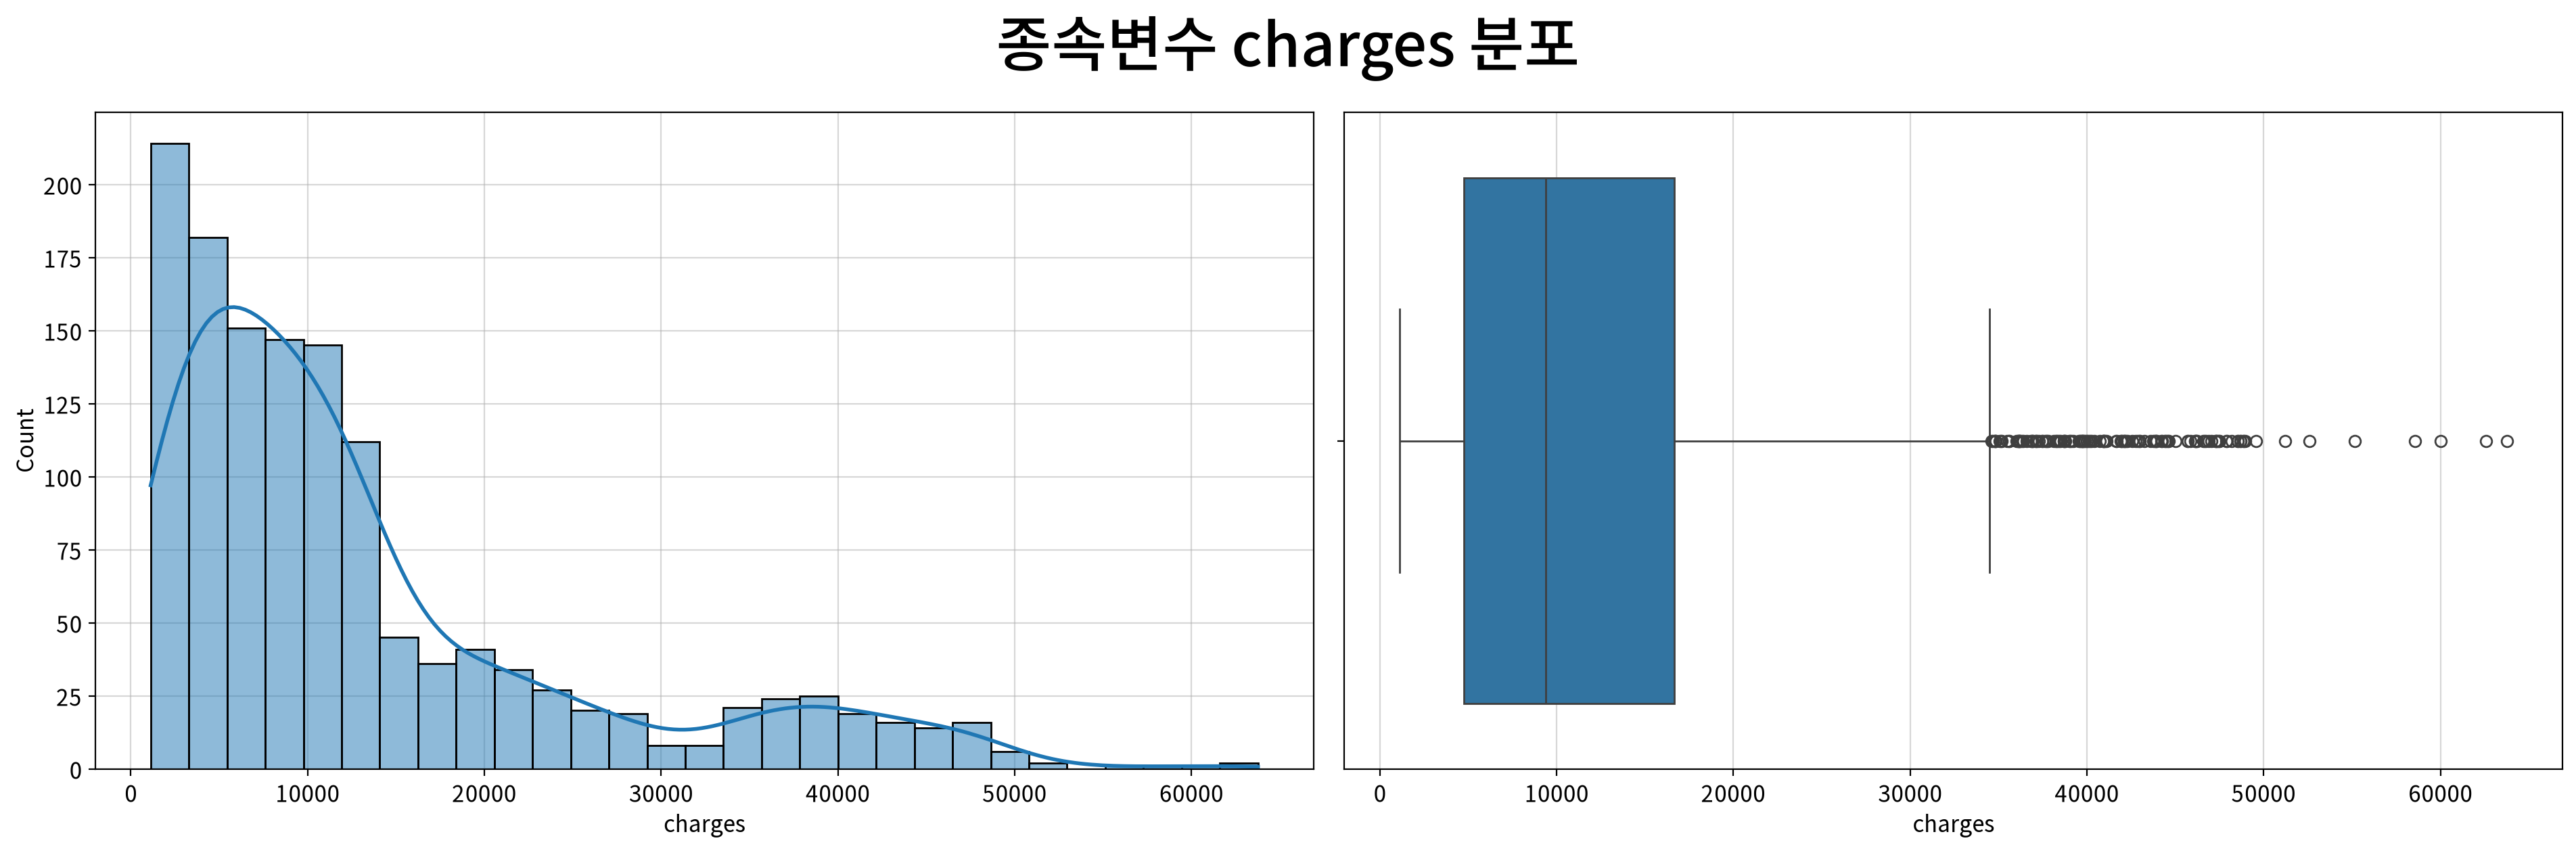

,charges
count,1337.0
mean,13279.121487
std,12110.359656
min,1121.8739
25%,4746.344
50%,9386.1613
75%,16657.71745
max,63770.42801
rel_diff,0.414755
rdiff_flag,diff


In [17]:
## 1행 2열 서브플롯 구성
## -> 그래프 크기는 서브플롯 중 하나의 크기(전체 크기는 가로 960 x 2가 됨)
fig, ax = my_plot.init(rows=1, cols=2,
            title=f"종속변수 {target} 분포", width=960, height=640)
my_plot.histplot(data=df, x=target, kde=True, ax=ax[0])
my_plot.boxplot(data=df, x=target, ax=ax[1])
my_plot.show()

## 연속형 변수 기술통계량에서 종속변수에 대한 부분만 추출
num_desc[num_desc.index == target].T

**해석**

- **분포 모양:** `charges`는 **우편향 분포**를 보인다(왜도 +1.52, 첨도 +1.60). 낮은 보험료 구간에 관측치가 많이 분포하고, 높은 보험료 방향으로 꼬리가 길게 나타난다.
- **이상치:** IQR 기준 상단 이상치가 **139건(약 10.4%)** 확인되었으며, 하단 이상치는 없다. 실제 고액 보험료 관측치일 가능성이 있어 임의로 삭제하지 않는다.
- **중심수준:** 평균은 약 **13,279달러**, 중앙값은 약 **9,386달러**로 평균이 더 높다. 높은 보험료 관측치의 영향으로 평균이 위쪽으로 끌려간 것으로 볼 수 있다.
- **조치:** 우측 꼬리가 뚜렷하고 `log_need = log`로 확인되어 **로그변환 후보 변수**로 설정한다. 이후 선형회귀에서 원자료와 로그변환 자료를 비교한다.
- **해석 방식의 변화:** 종속변수 `charges`를 로그변환한 모델에서는 회귀계수를 보험료의 **절대 금액 변화가 아닌 비율 또는 % 변화** 중심으로 해석한다.

##### 6) 연속형 독립변수에 대한 단변량 분석

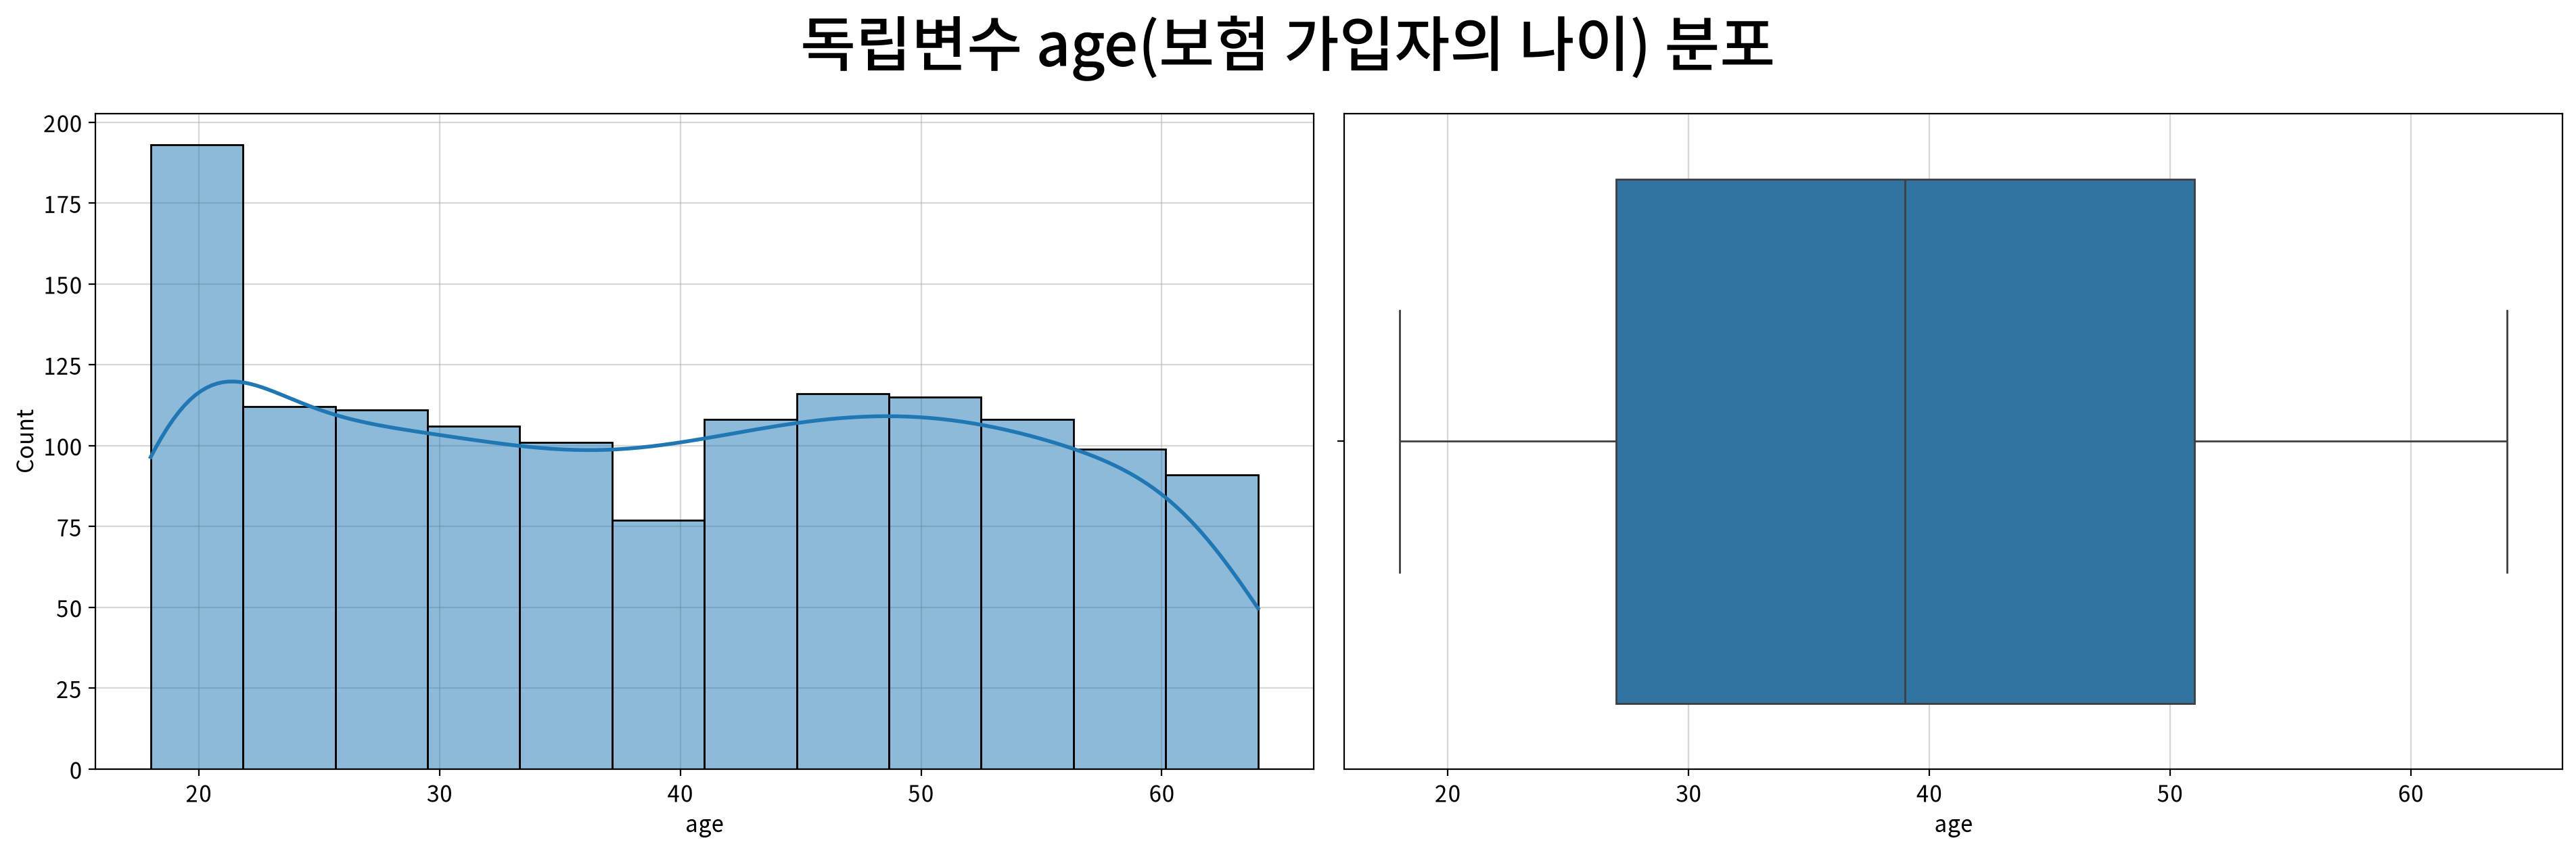

,age
count,1337.0
mean,39.222139
std,14.044333
min,18.0
25%,27.0
50%,39.0
75%,51.0
max,64.0
rel_diff,0.005696
rdiff_flag,similar


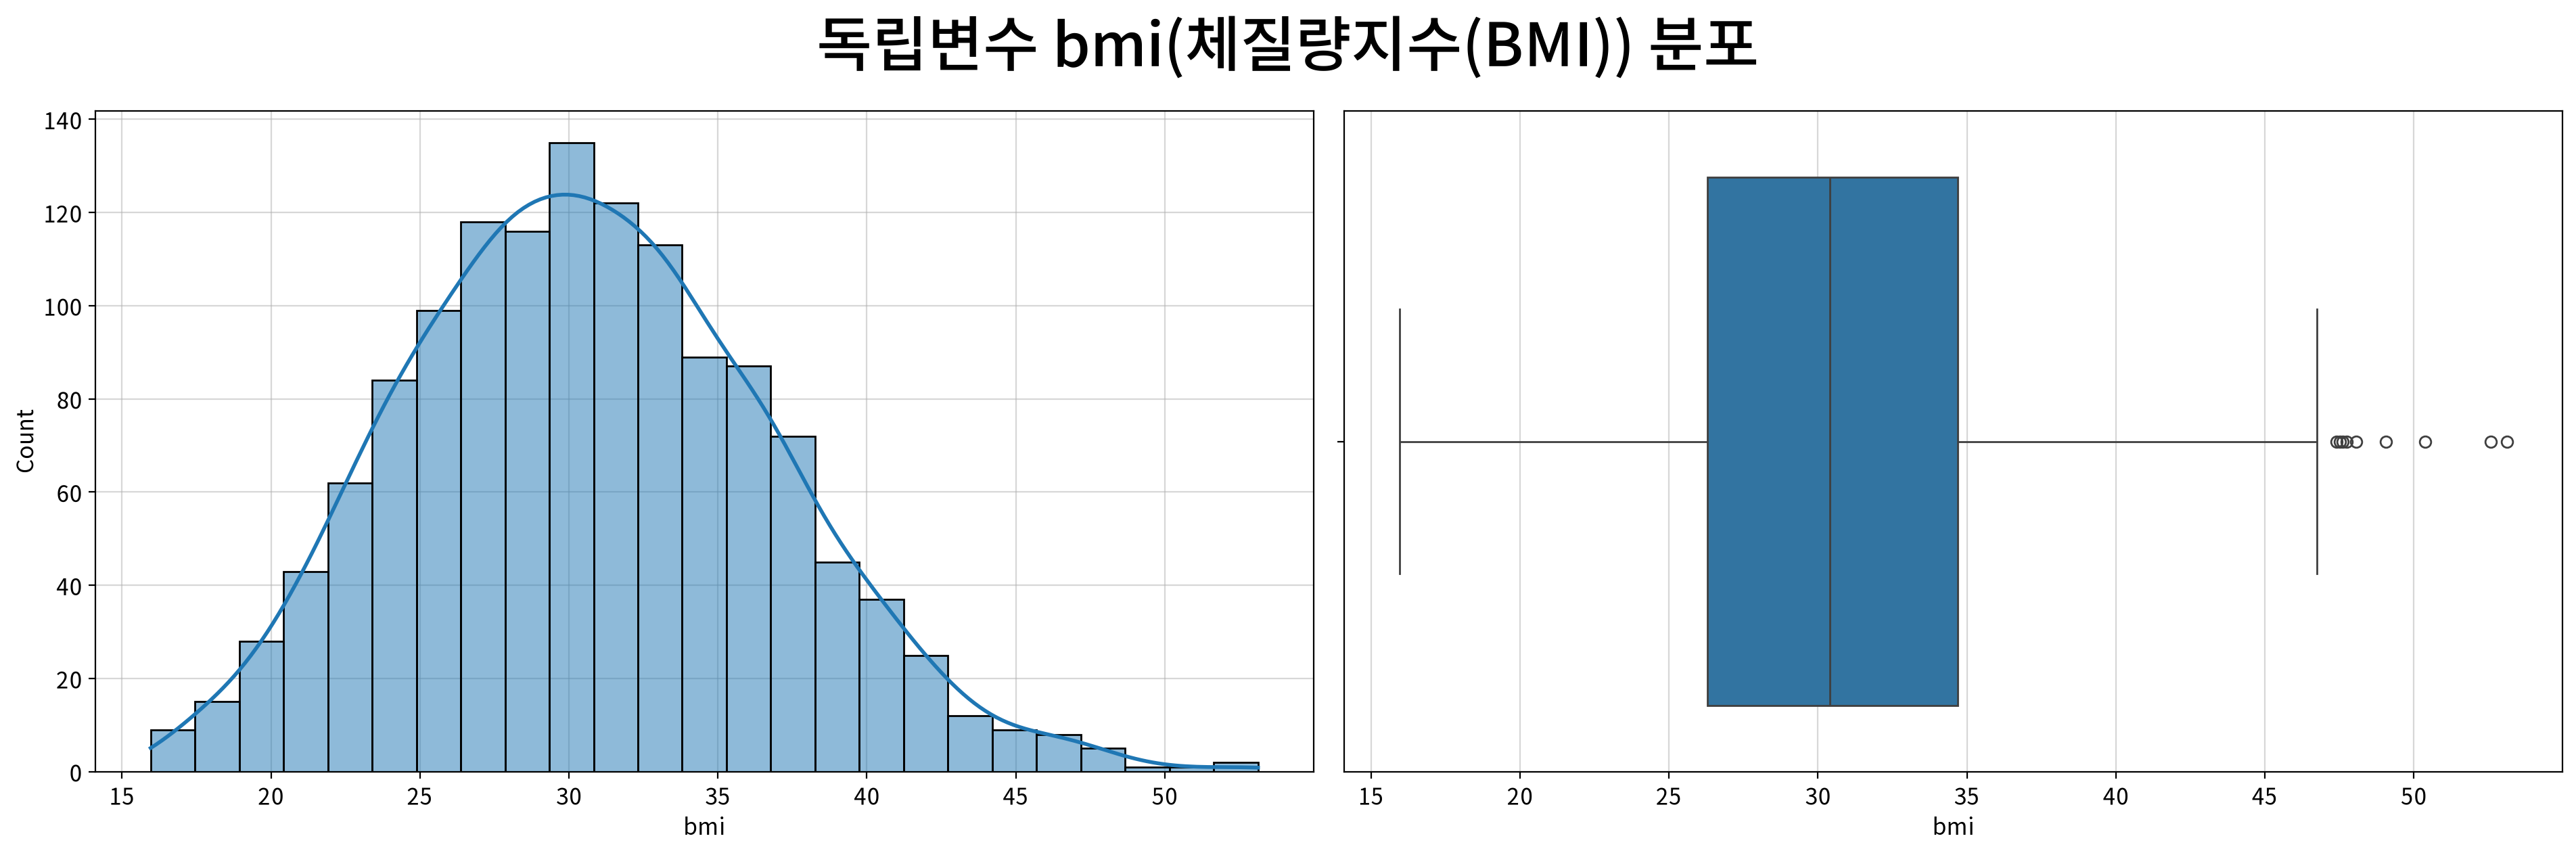

,bmi
count,1337.0
mean,30.663452
std,6.100468
min,15.96
25%,26.29
50%,30.4
75%,34.7
max,53.13
rel_diff,0.008666
rdiff_flag,similar


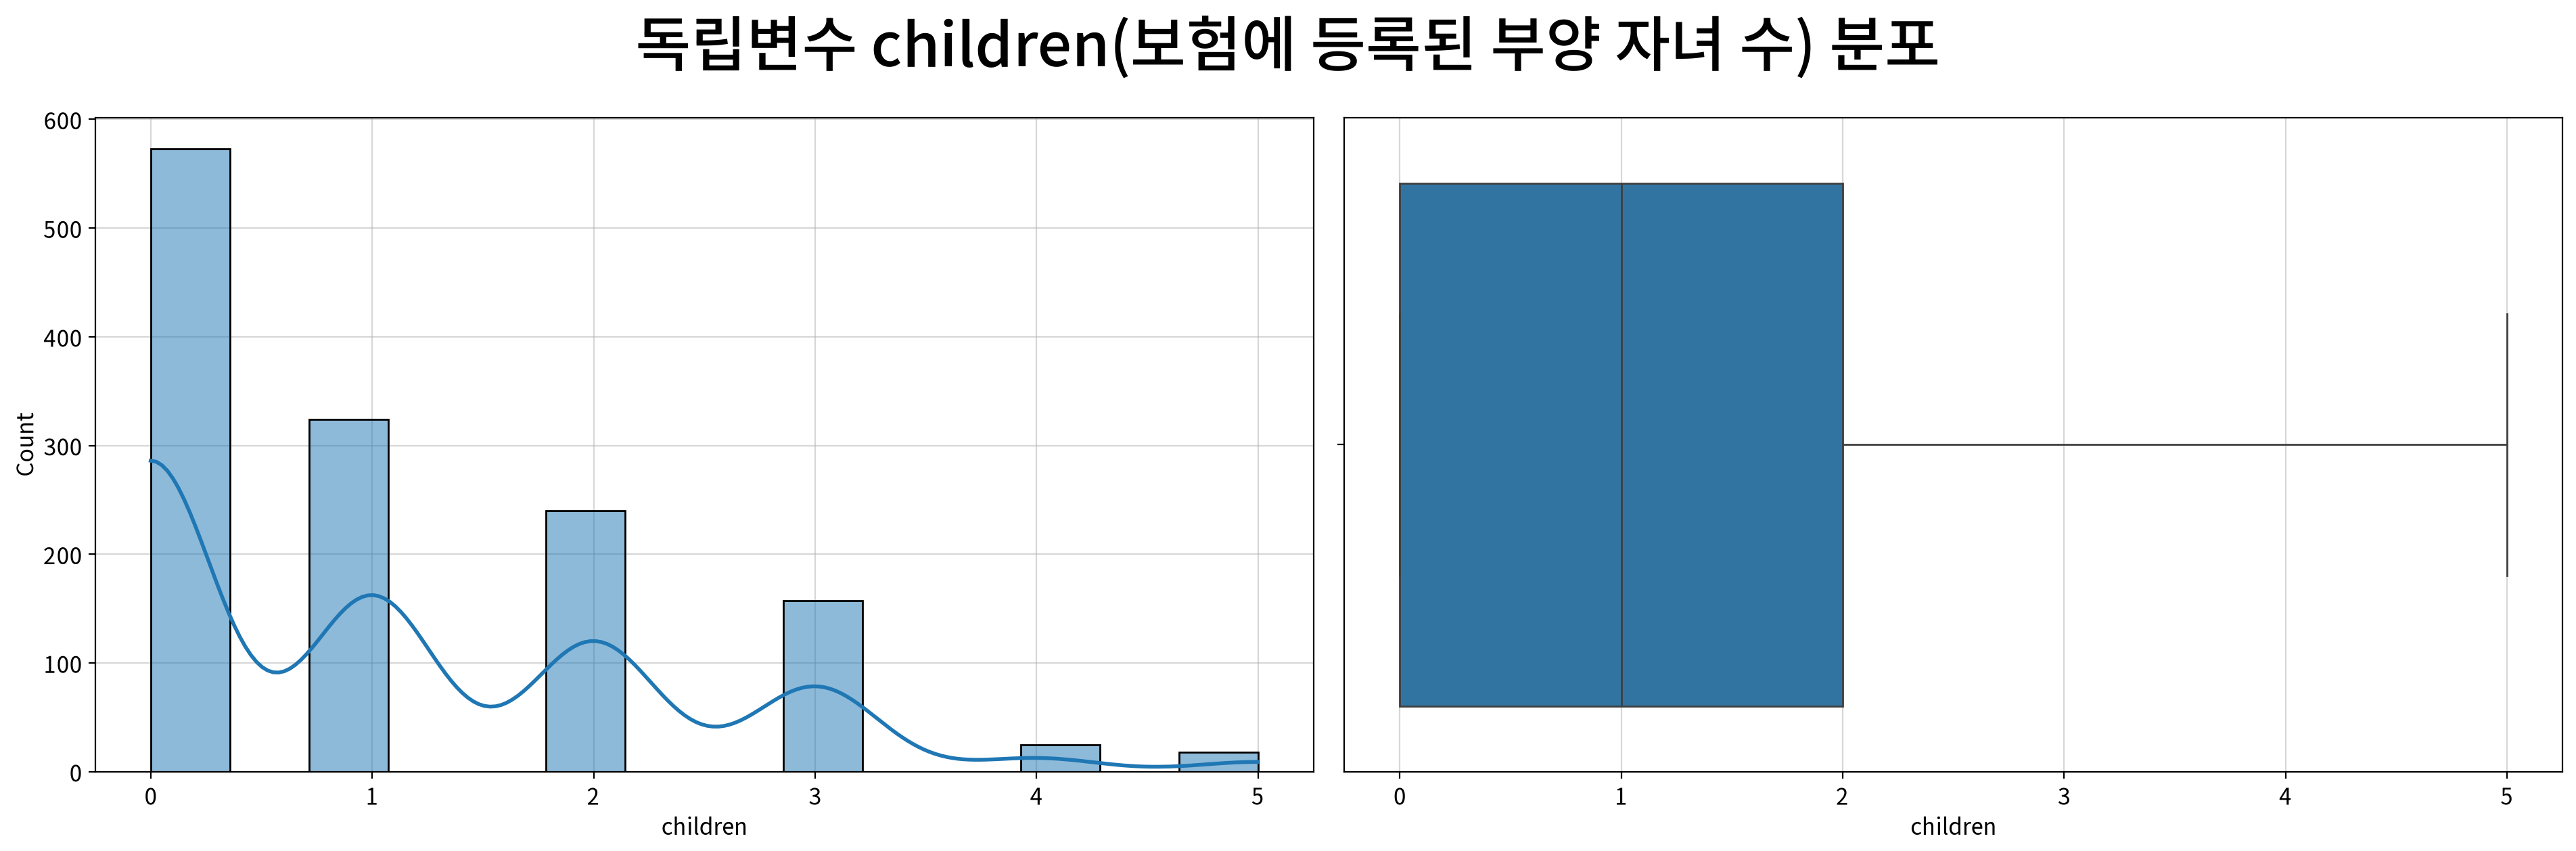

,children
count,1337.0
mean,1.095737
std,1.205571
min,0.0
25%,0.0
50%,1.0
75%,2.0
max,5.0
rel_diff,0.095737
rdiff_flag,similar


In [18]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc[num_desc.index == f].T)

##### 7) 명목형 독립변수에 대한 단변량 분석

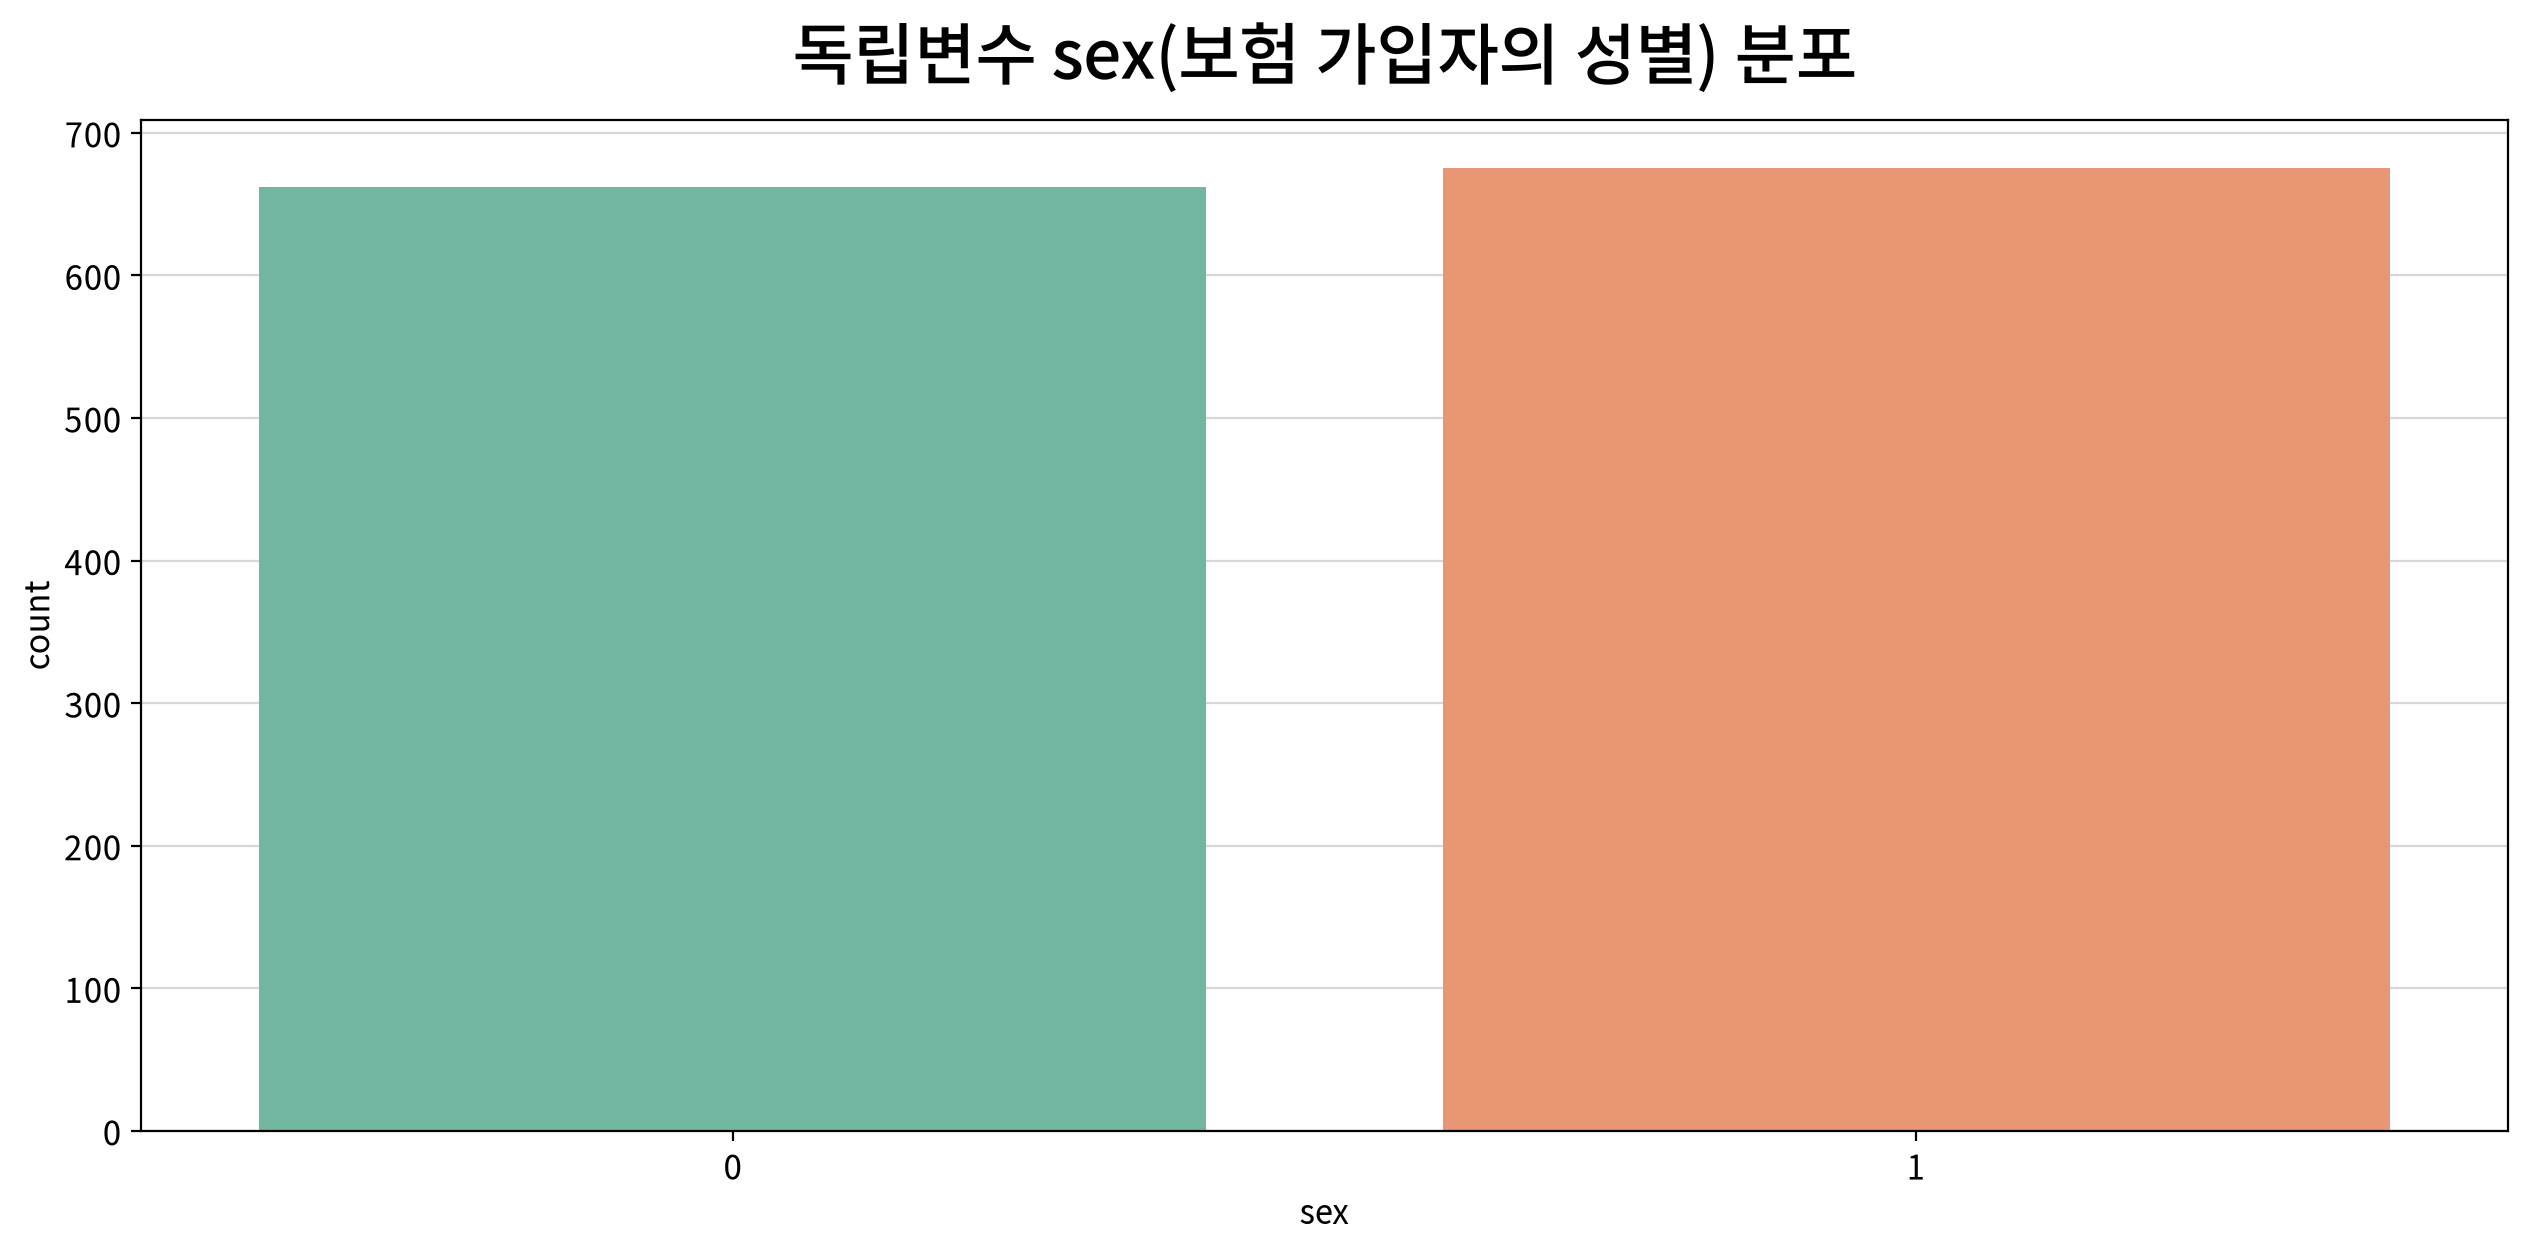

,count,unique,top,freq
sex,1337,2,1,675


,빈도,비율
sex,,
1,675,0.504862
0,662,0.495138


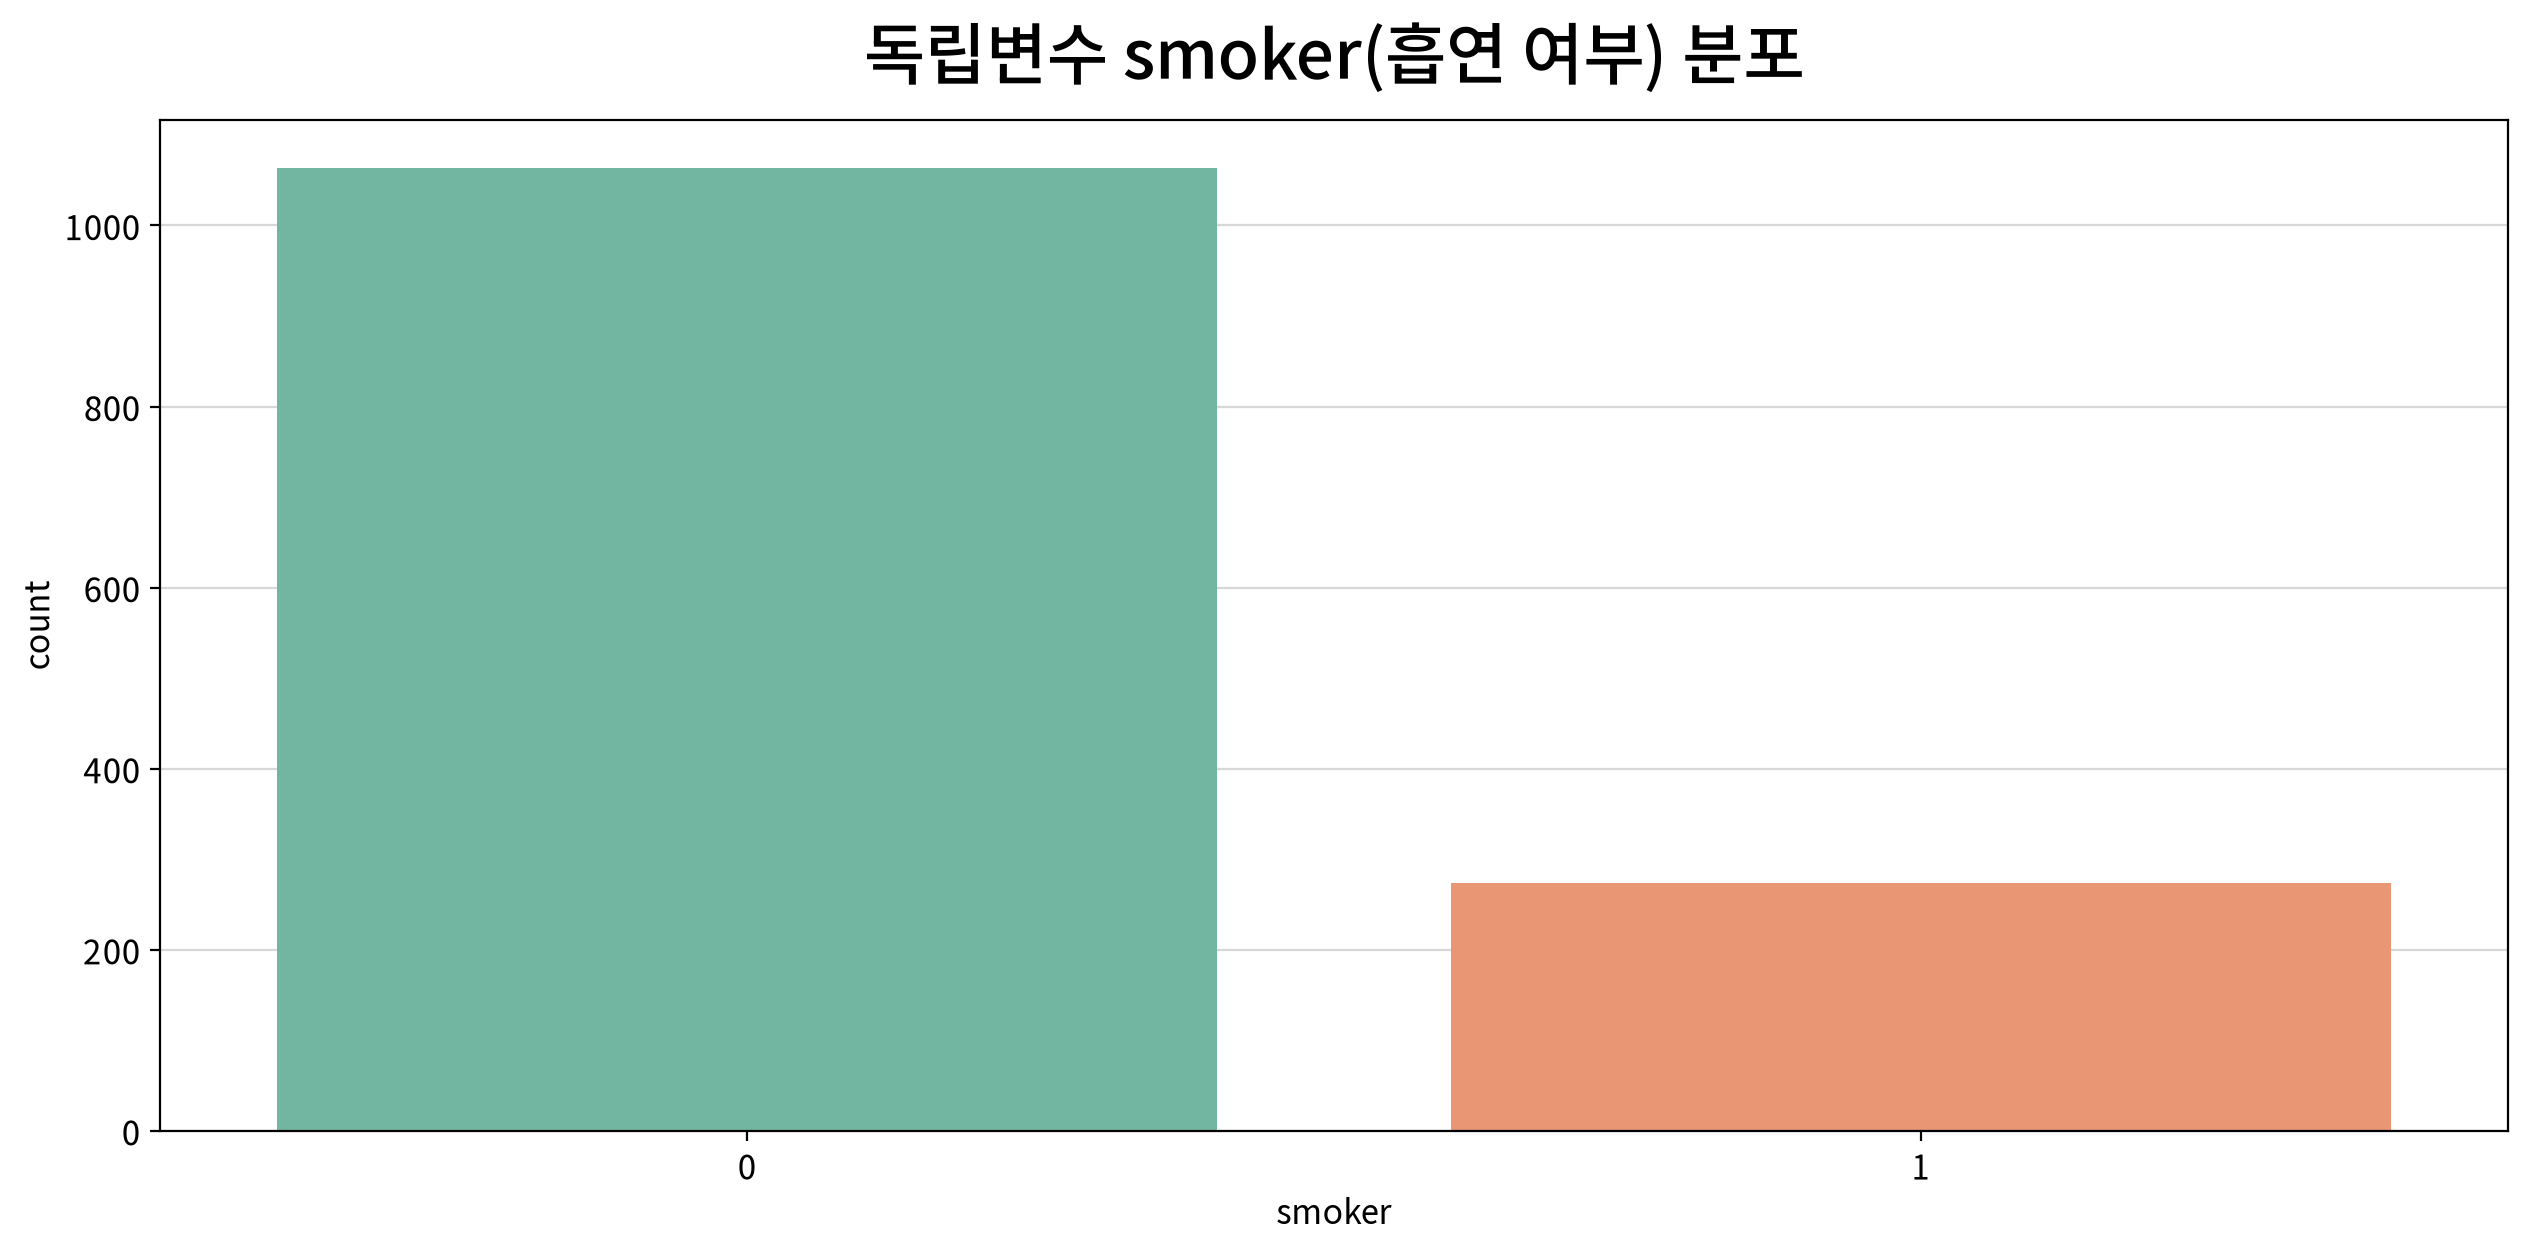

,count,unique,top,freq
smoker,1337,2,0,1063


,빈도,비율
smoker,,
0,1063,0.795064
1,274,0.204936


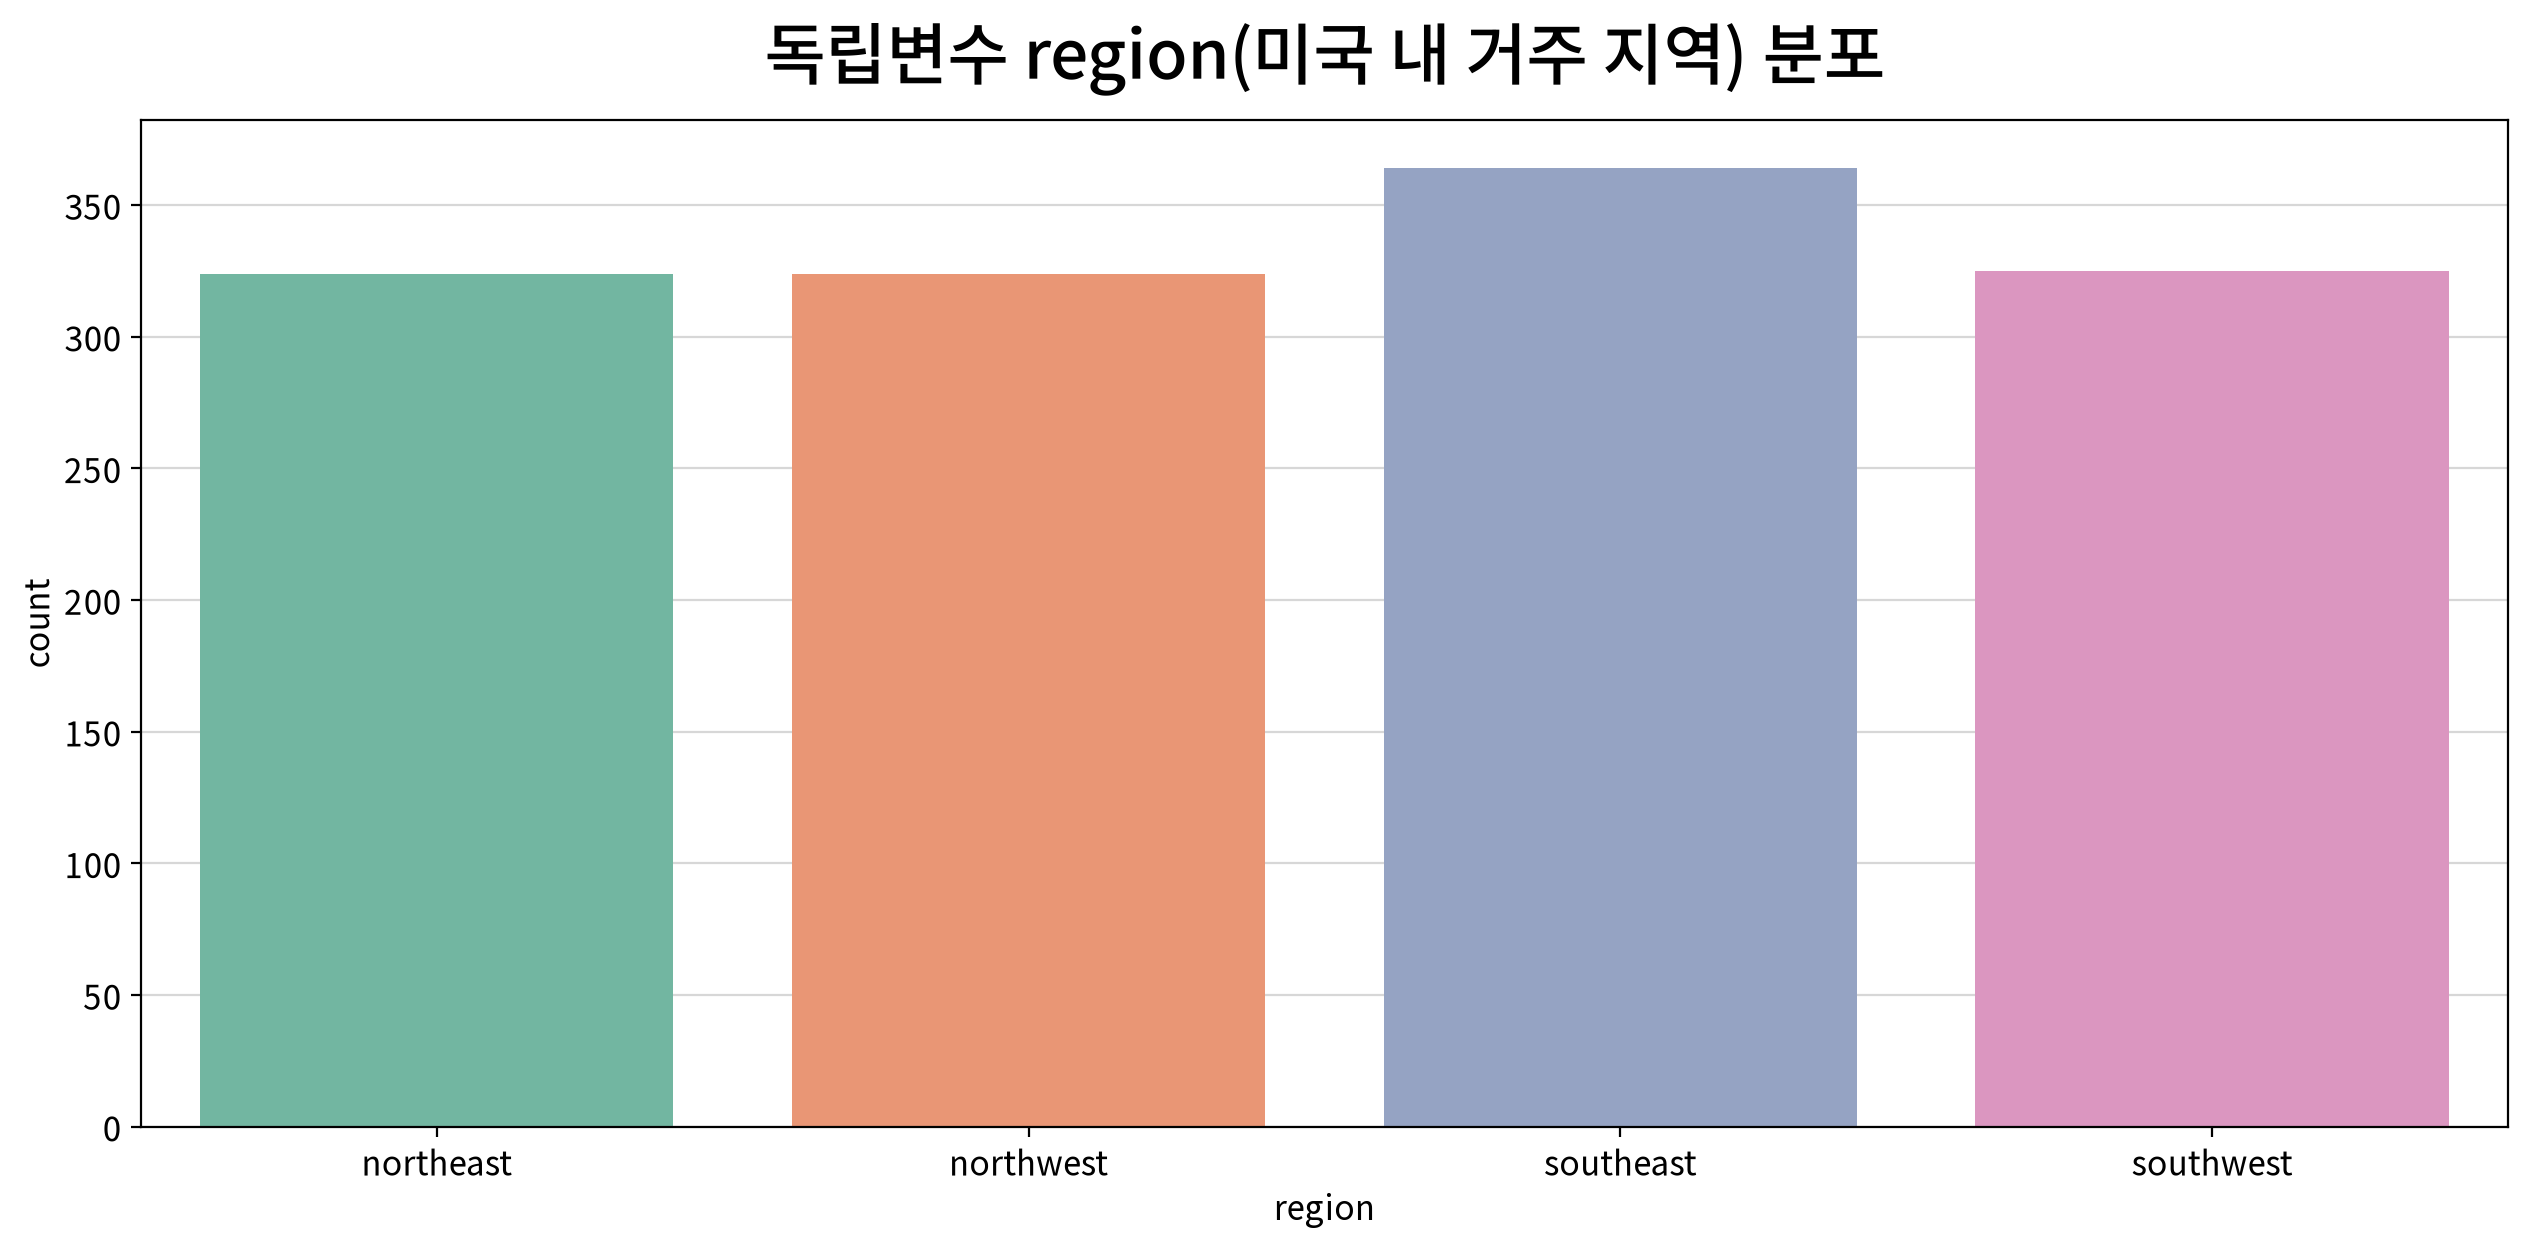

,count,unique,top,freq
region,1337,4,southeast,364


,빈도,비율
region,,
southeast,364,0.272251
southwest,325,0.243082
northwest,324,0.242334
northeast,324,0.242334


In [19]:
for n in nominal_cols:
    ## 명목형 분포는 카운트 플롯으로 처리한다.
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", title=f"독립변수 {n}({column_means[n]}) 분포")

    ## 명목형 기술통계량
    display(cat_desc[[n]].T)

    ## 추가적으로 빈도표 생성
    freq = df[n].value_counts().rename("빈도").to_frame()
    ## value_counts(normalize=True)
    ## --> 전체 고유값의 개수(빈도수) 대신 전체 데이터의 비율을 계산
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq)

**해석**

| 변수 | 분포 모양(왜도) | 봉우리·집중 구간 | 이상치 | 판단·조치 |
|---|---|---|---|---|
| `age` | 거의 대칭 (+0.05) | 전 연령대에 비교적 고르게 분포 | 0건 | 변환 불필요 |
| `bmi` | 거의 대칭 (+0.28) | **30 부근 단봉** | 9건(0.7%) | 변환 불필요, 이상치는 실제 가능한 범위로 판단하여 유지 |
| `children` | 우편향 (+0.94) | **0~2명에 집중** | 0건 | 이산형 변수이므로 `log1p` 판정에도 원자료 유지 |
| `sex` |  | 0: 662건 / 1: 675건 |  | **두 집단이 거의 균형** |
| `smoker` |  | 0: 1,063건 / 1: 274건 |  | **비흡연자에 편중** - 집단 비교 시 표본 수 차이 주의 |
| `region` |  | 4개 지역이 324~364건 수준 |  | **지역별 분포가 비교적 균등** |

- 연속형 변수 중 `age`와 `bmi`는 왜도가 작아 분포의 비대칭성이 크지 않으며 별도의 변환이 필요하지 않다.
- `children`은 우측 꼬리가 나타나지만 **0~5명의 제한된 값을 가지는 이산형 변수**이므로 자동 로그변환은 적용하지 않는다.
- 명목형 변수에서는 `sex`와 `region`의 분포가 비교적 균등한 반면, `smoker`는 비흡연자가 약 **79.5%**, 흡연자가 약 **20.5%**로 집단 크기 차이가 크다.

#### 4-2. 변수 간 관계

##### 1) 상관분석 (x: 연속형 독립변수 → y: 연속형 종속변수)

##### ▶︎ age(보험 가입자의 나이) → charges

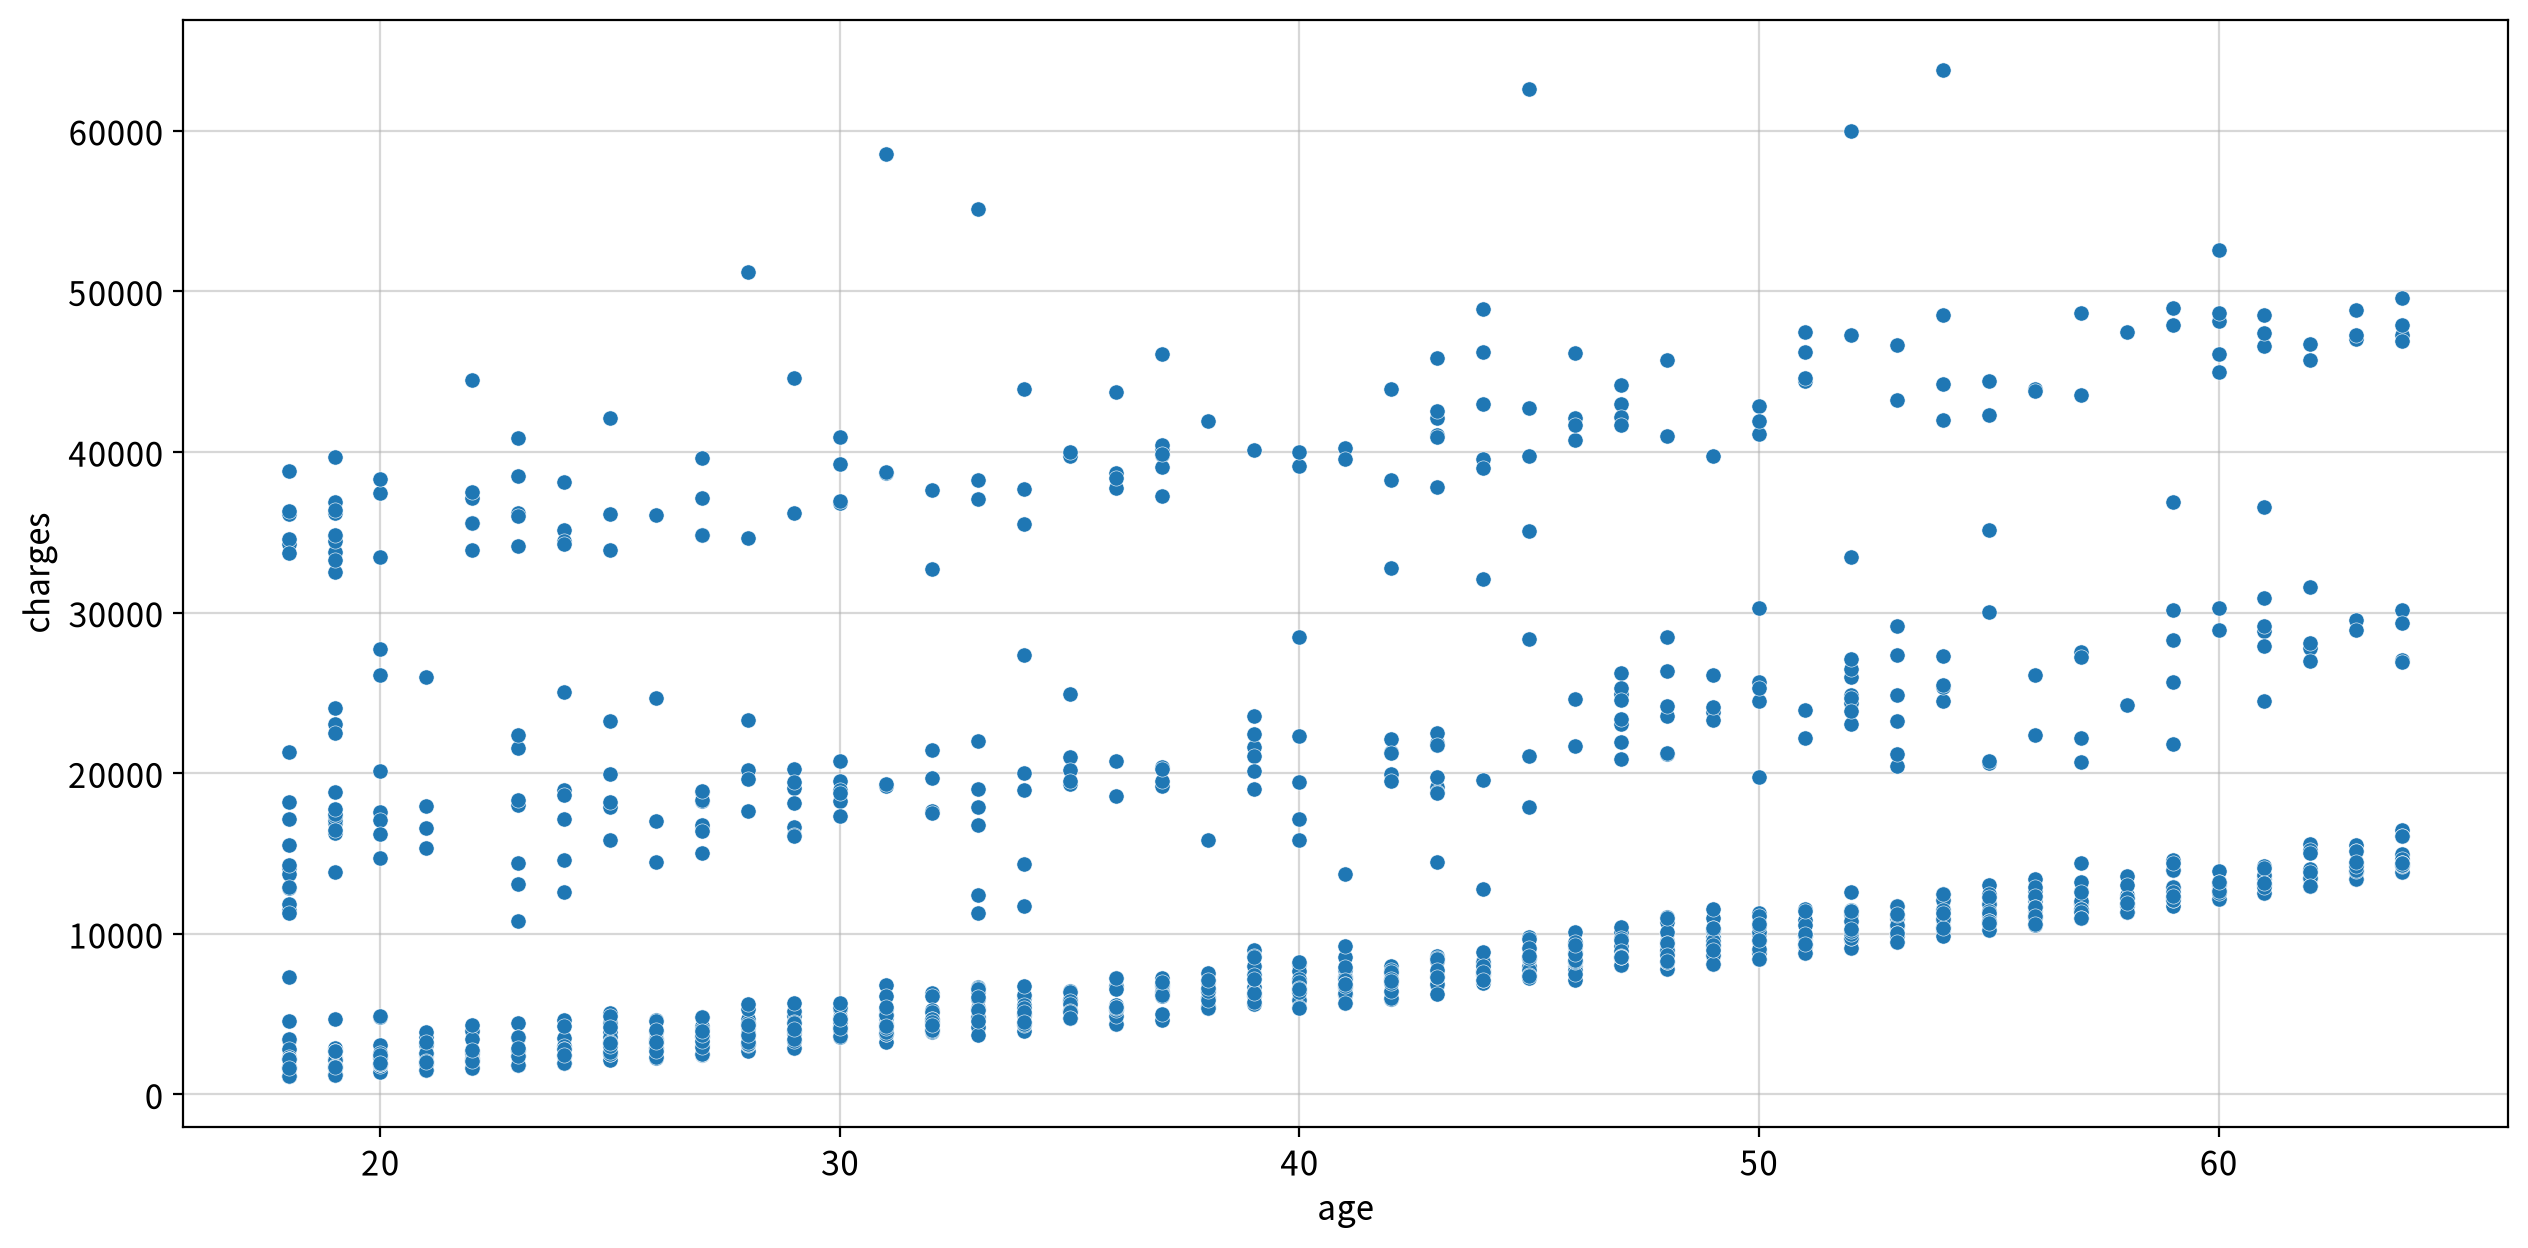

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
age,charges,Spearman,0.5335,0.0,Moderate,True,False,False,True,True


##### ▶︎ bmi(체질량지수(BMI)) → charges

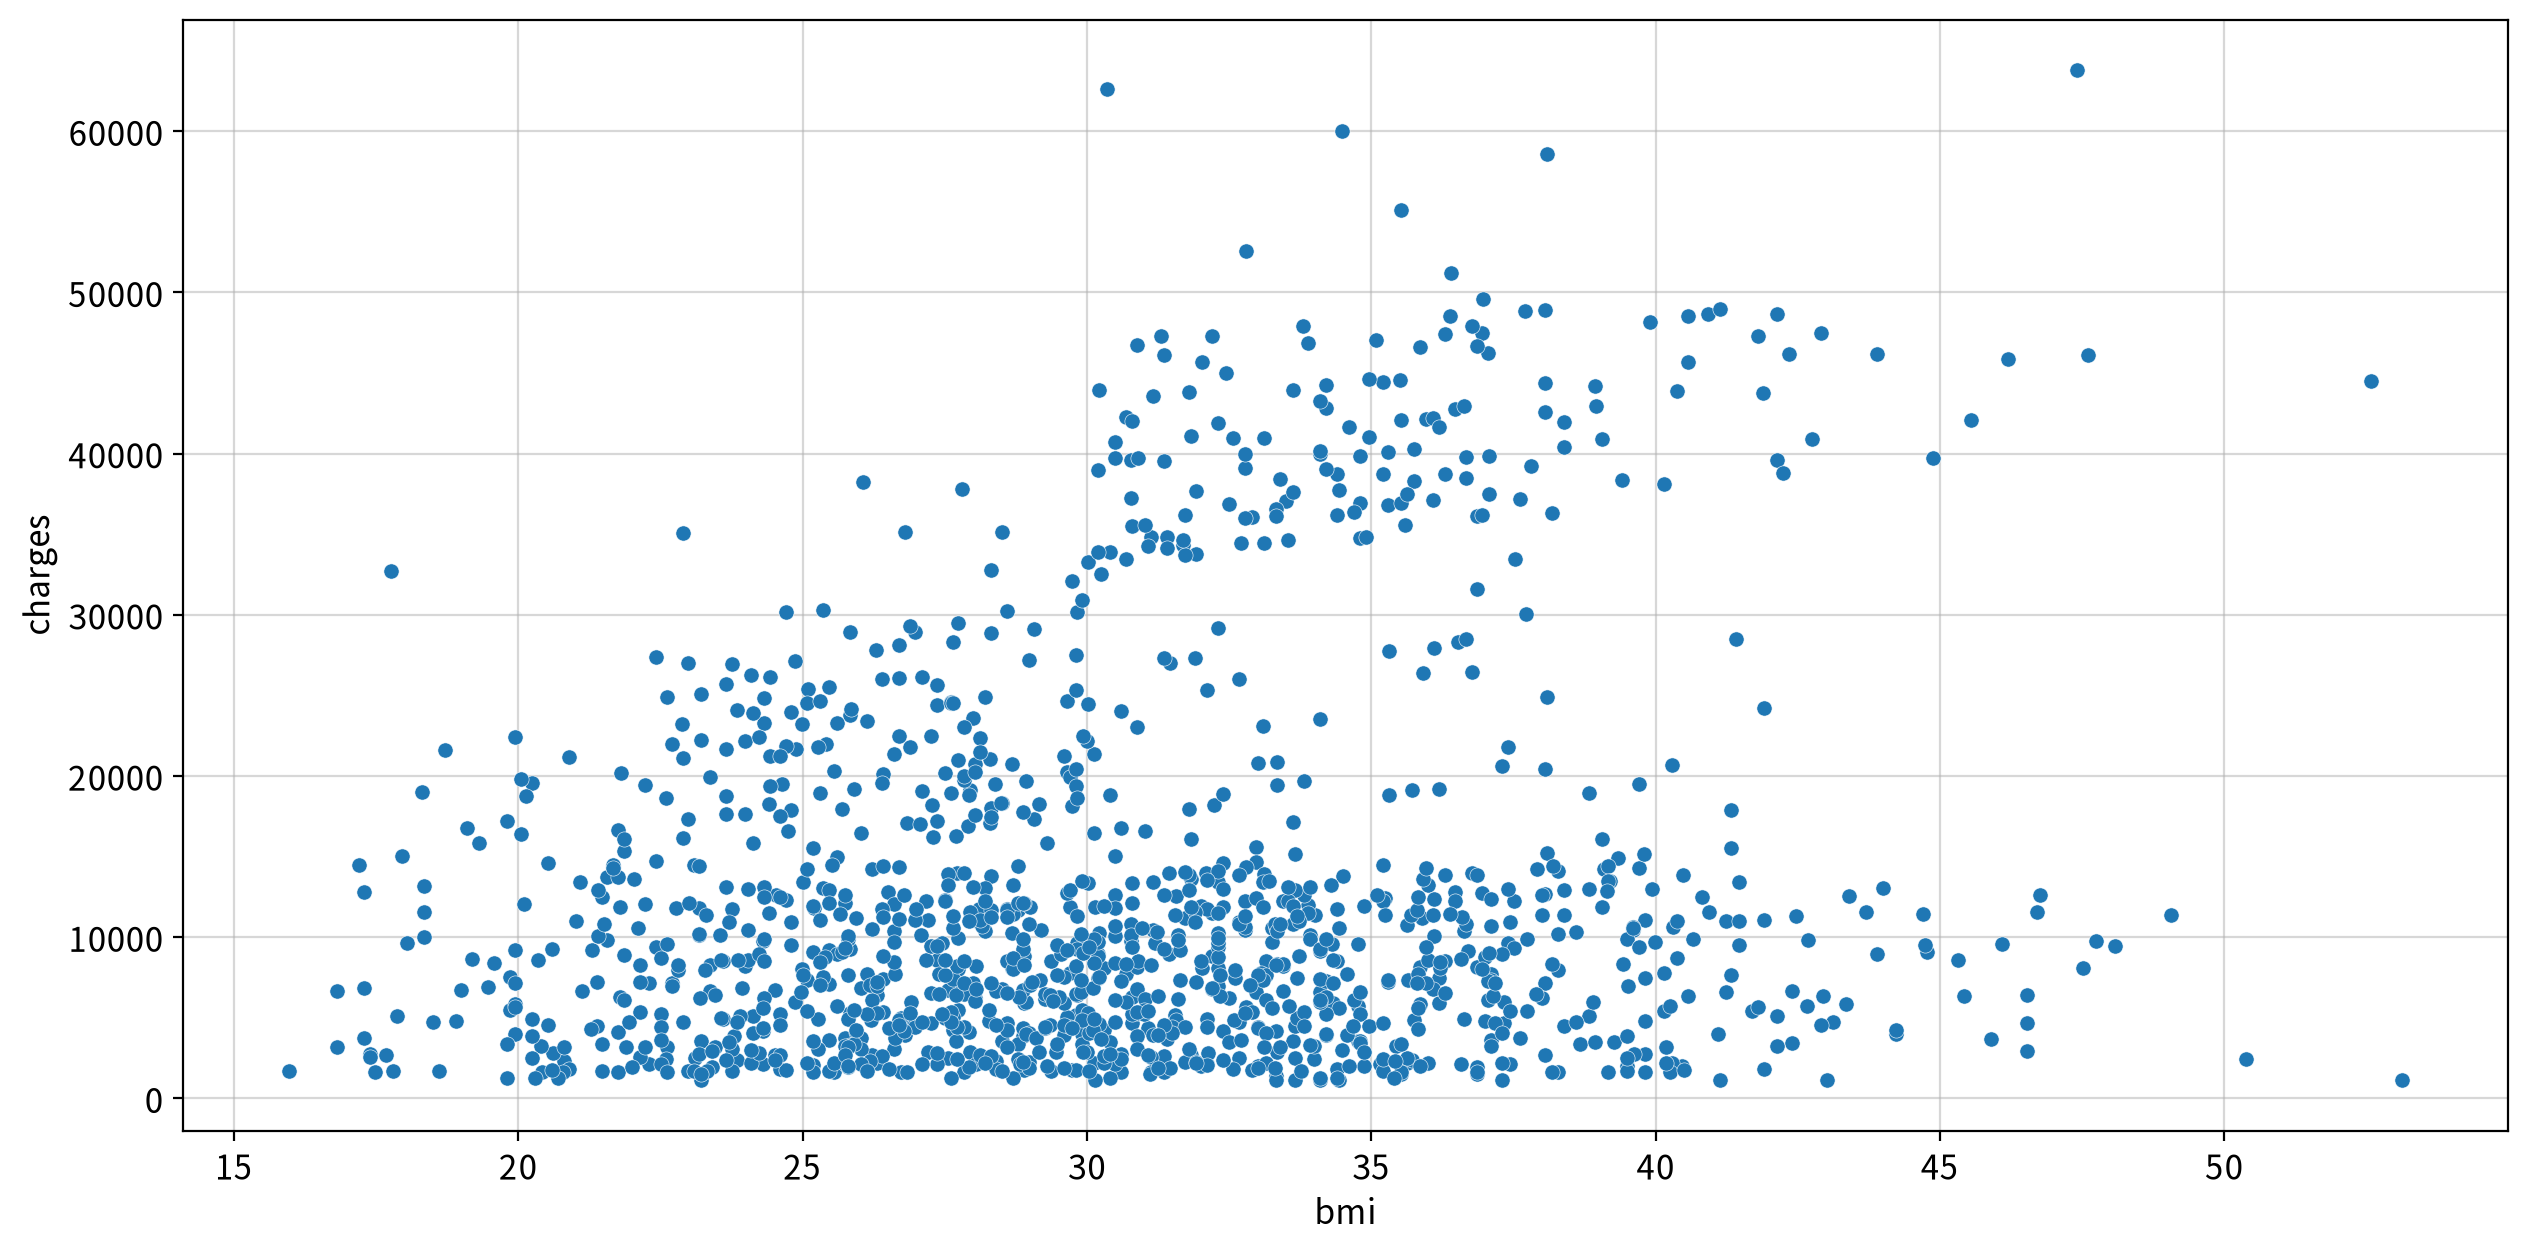

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
bmi,charges,Spearman,0.1196,0.0,Weak,True,False,False,True,True


##### ▶︎ children(보험에 등록된 부양 자녀 수) → charges

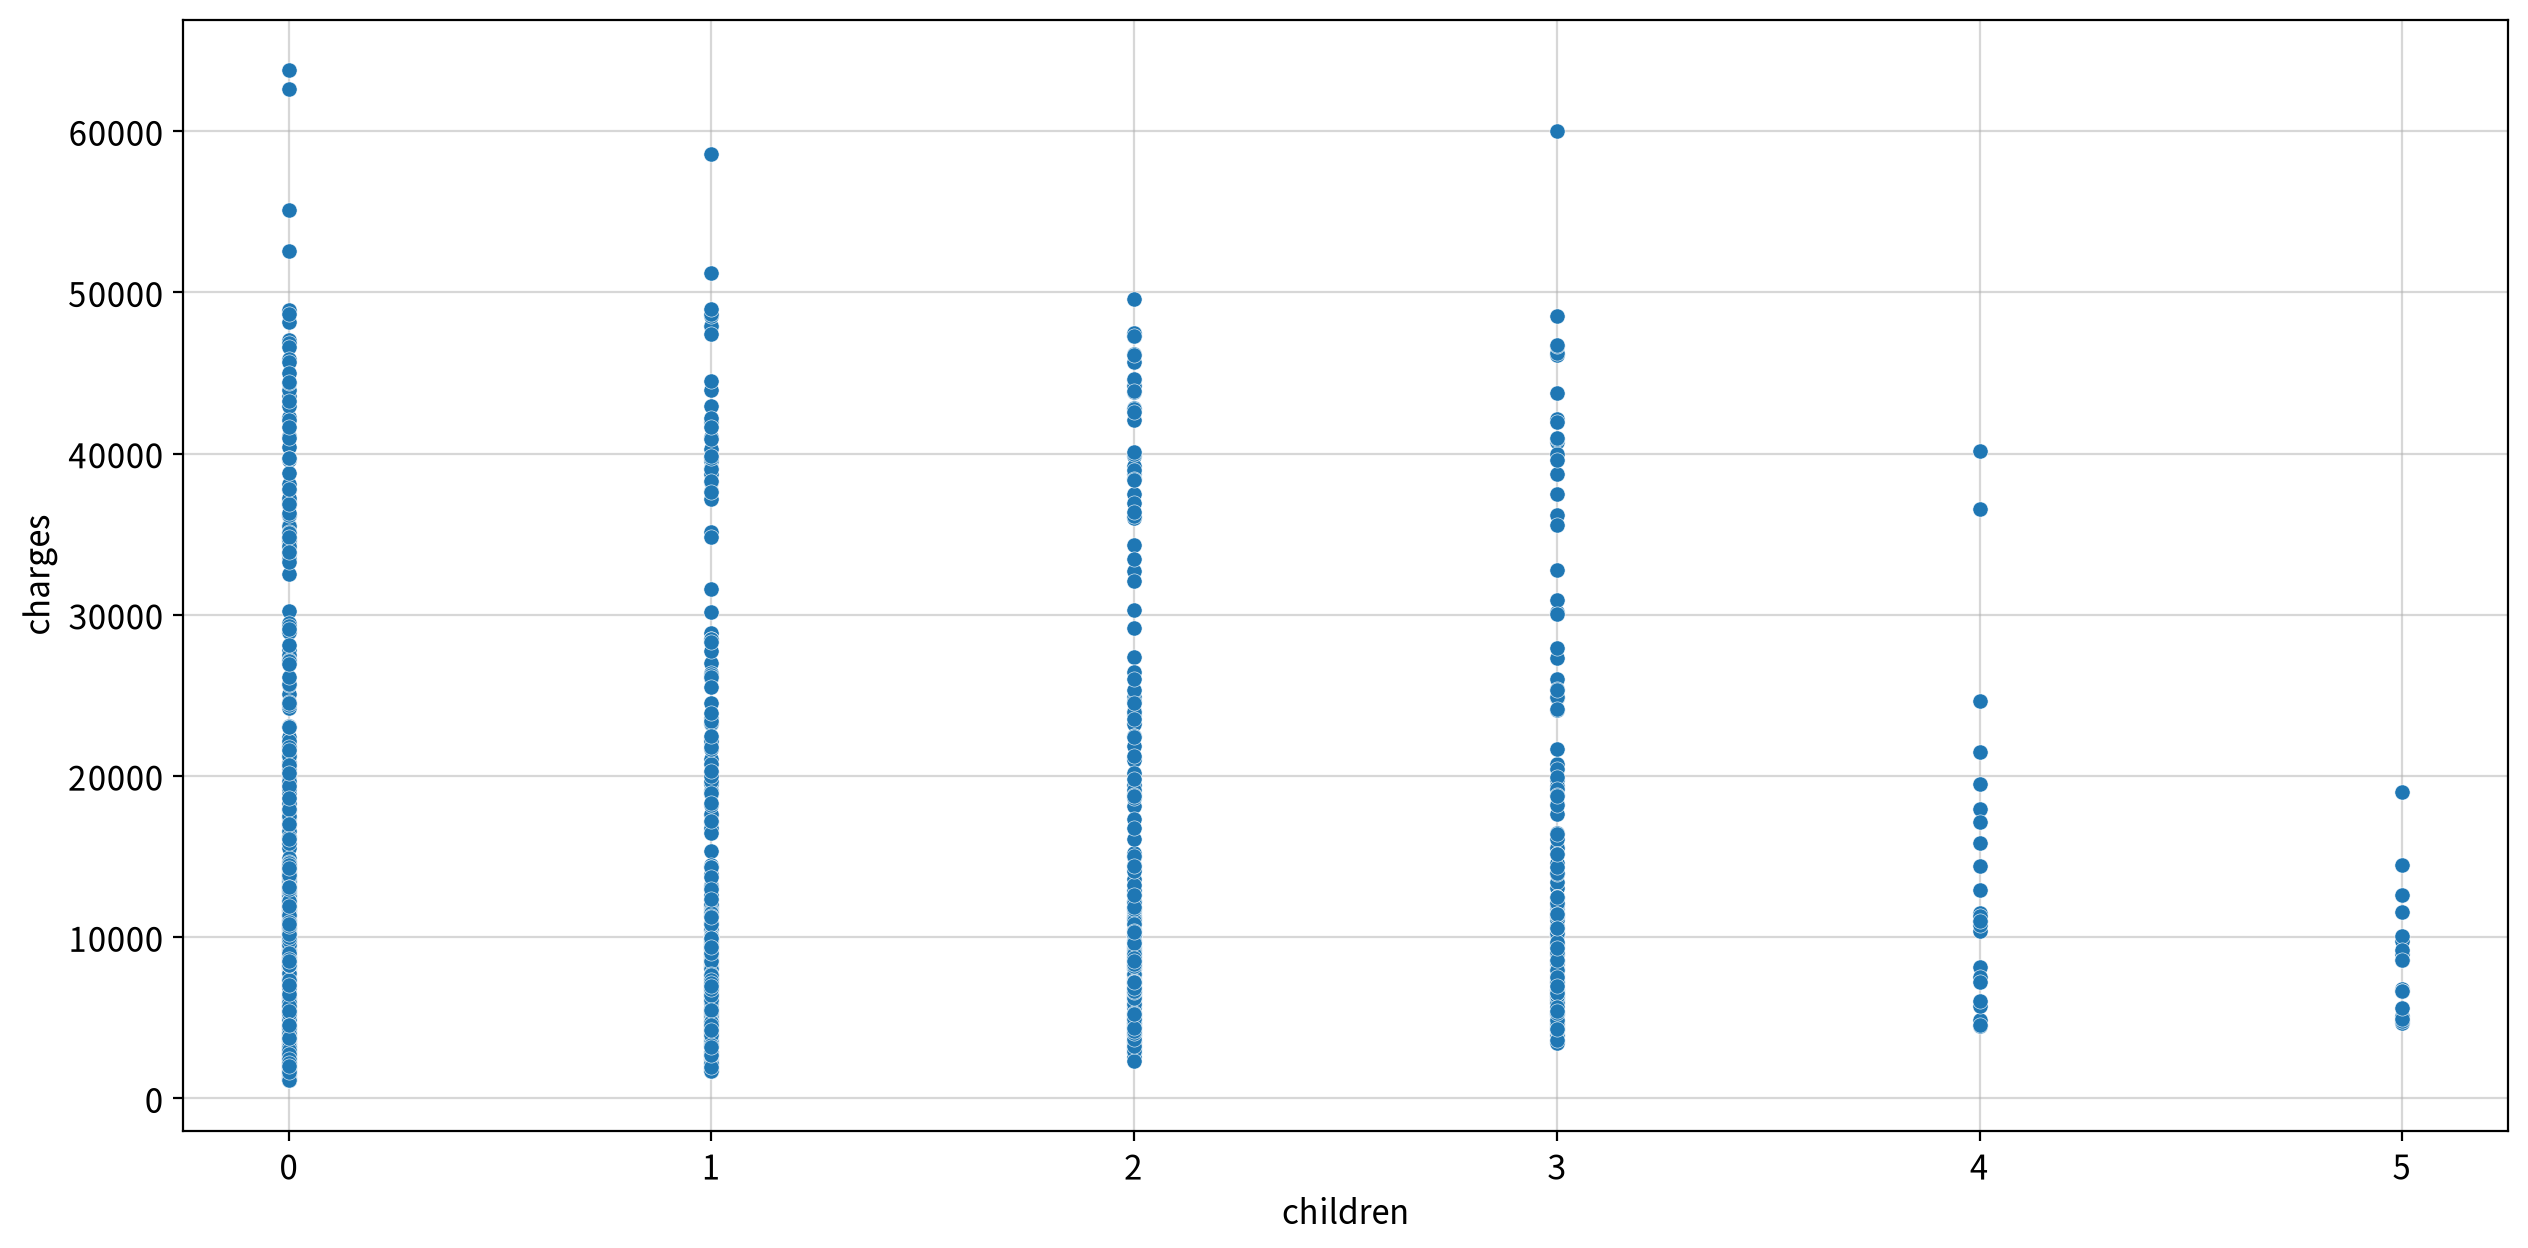

,,method,coef,p-value,strength,significant,normality_x,normality_y,linearity,influential
x,y,,,,,,,,,
children,charges,Spearman,0.1322,0.0,Weak,True,False,False,False,True


In [20]:
## 연속형 독립변수 이름을 탐색하면서 반복
for f in continuous_cols:
    ## 빈 줄 출력용
    print()

    ## 분석 단위 제목 출력
    display(Markdown(f"##### ▶︎ {f}({column_means[f]}) → {target}"))

    ## 시각화
    my_plot.scatterplot(data=df, x=f, y=target, outline=False,
                        ## 데이터 밀도에 따라 외곽선 굵기와 점 크기 조절
                        linewidth=0.2, size=30)

    ## my_stats는 시각화까지 일괄처리 한다.
    display(my_stats.correlation(df, x=f, y=target, plot=False))

**해석**

| 변수 | 선형/비선형 | 단조성 | 산포 | 특징 | 채택 여부 |
|---|---|---|---|---|---|
| `age` | 완전한 선형은 아님 | **양의 단조↑** (ρ = +0.534) | 큼 | 보험료가 여러 층으로 나뉘지만 전반적으로 나이가 증가할수록 상승 | ✅ **채택 (우선)** |
| `bmi` | 뚜렷한 선형성 없음 | 약한 양의 단조↑ (ρ = +0.120) | **매우 큼** | 동일 BMI에서도 보험료 편차가 매우 크고 일부 고액 집단이 분리됨 | ✅ 채택 |
| `children` | 이산형·계단형 | 약한 양의 단조↑ (ρ = +0.132) | 큼 | 0~5의 정수값에 세로로 분포하며 뚜렷한 증가 추세는 약함 | 🟡 **영향력 낮음** |

- **종속변수와 상관이 가장 높은 변수:** `age`가 **ρ = +0.534(Moderate)**로 세 변수 중 가장 높은 양의 상관을 보인다. 나이가 증가할수록 `charges`도 전반적으로 증가하는 경향이 있다.
- **약한 상관 변수:** `bmi`(+0.120)와 `children`(+0.132)은 모두 통계적으로 유의하지만 상관의 크기는 **Weak** 수준으로, 단독으로 보험료를 설명하는 힘은 크지 않다.
- **산점도의 형태:** `age`와 `bmi` 모두 하나의 직선 주변에 관측치가 모이기보다 보험료 수준에 따라 여러 집단으로 나뉘는 모습이 보인다. 따라서 다른 변수, 특히 범주형 변수와의 관계를 함께 확인할 필요가 있다.
- `children`은 0~5의 값을 갖는 **이산형 변수**라 산점도가 세로 띠 형태로 나타난다. 상관계수가 낮아 보험료와의 단순 단조관계는 약하다.
- 세 변수 모두 p-value가 매우 작아 **통계적으로 유의한 관계**는 확인되지만, 통계적 유의성과 실제 관계의 강도는 구분해서 해석한다.

##### 2) T-Test (x: 2집단 명목형 독립변수 → y: 종속변수)

- 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.

##### ▶︎ sex(보험 가입자의 성별) → charges

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:6.945e-01 U_stat=2.207e+05


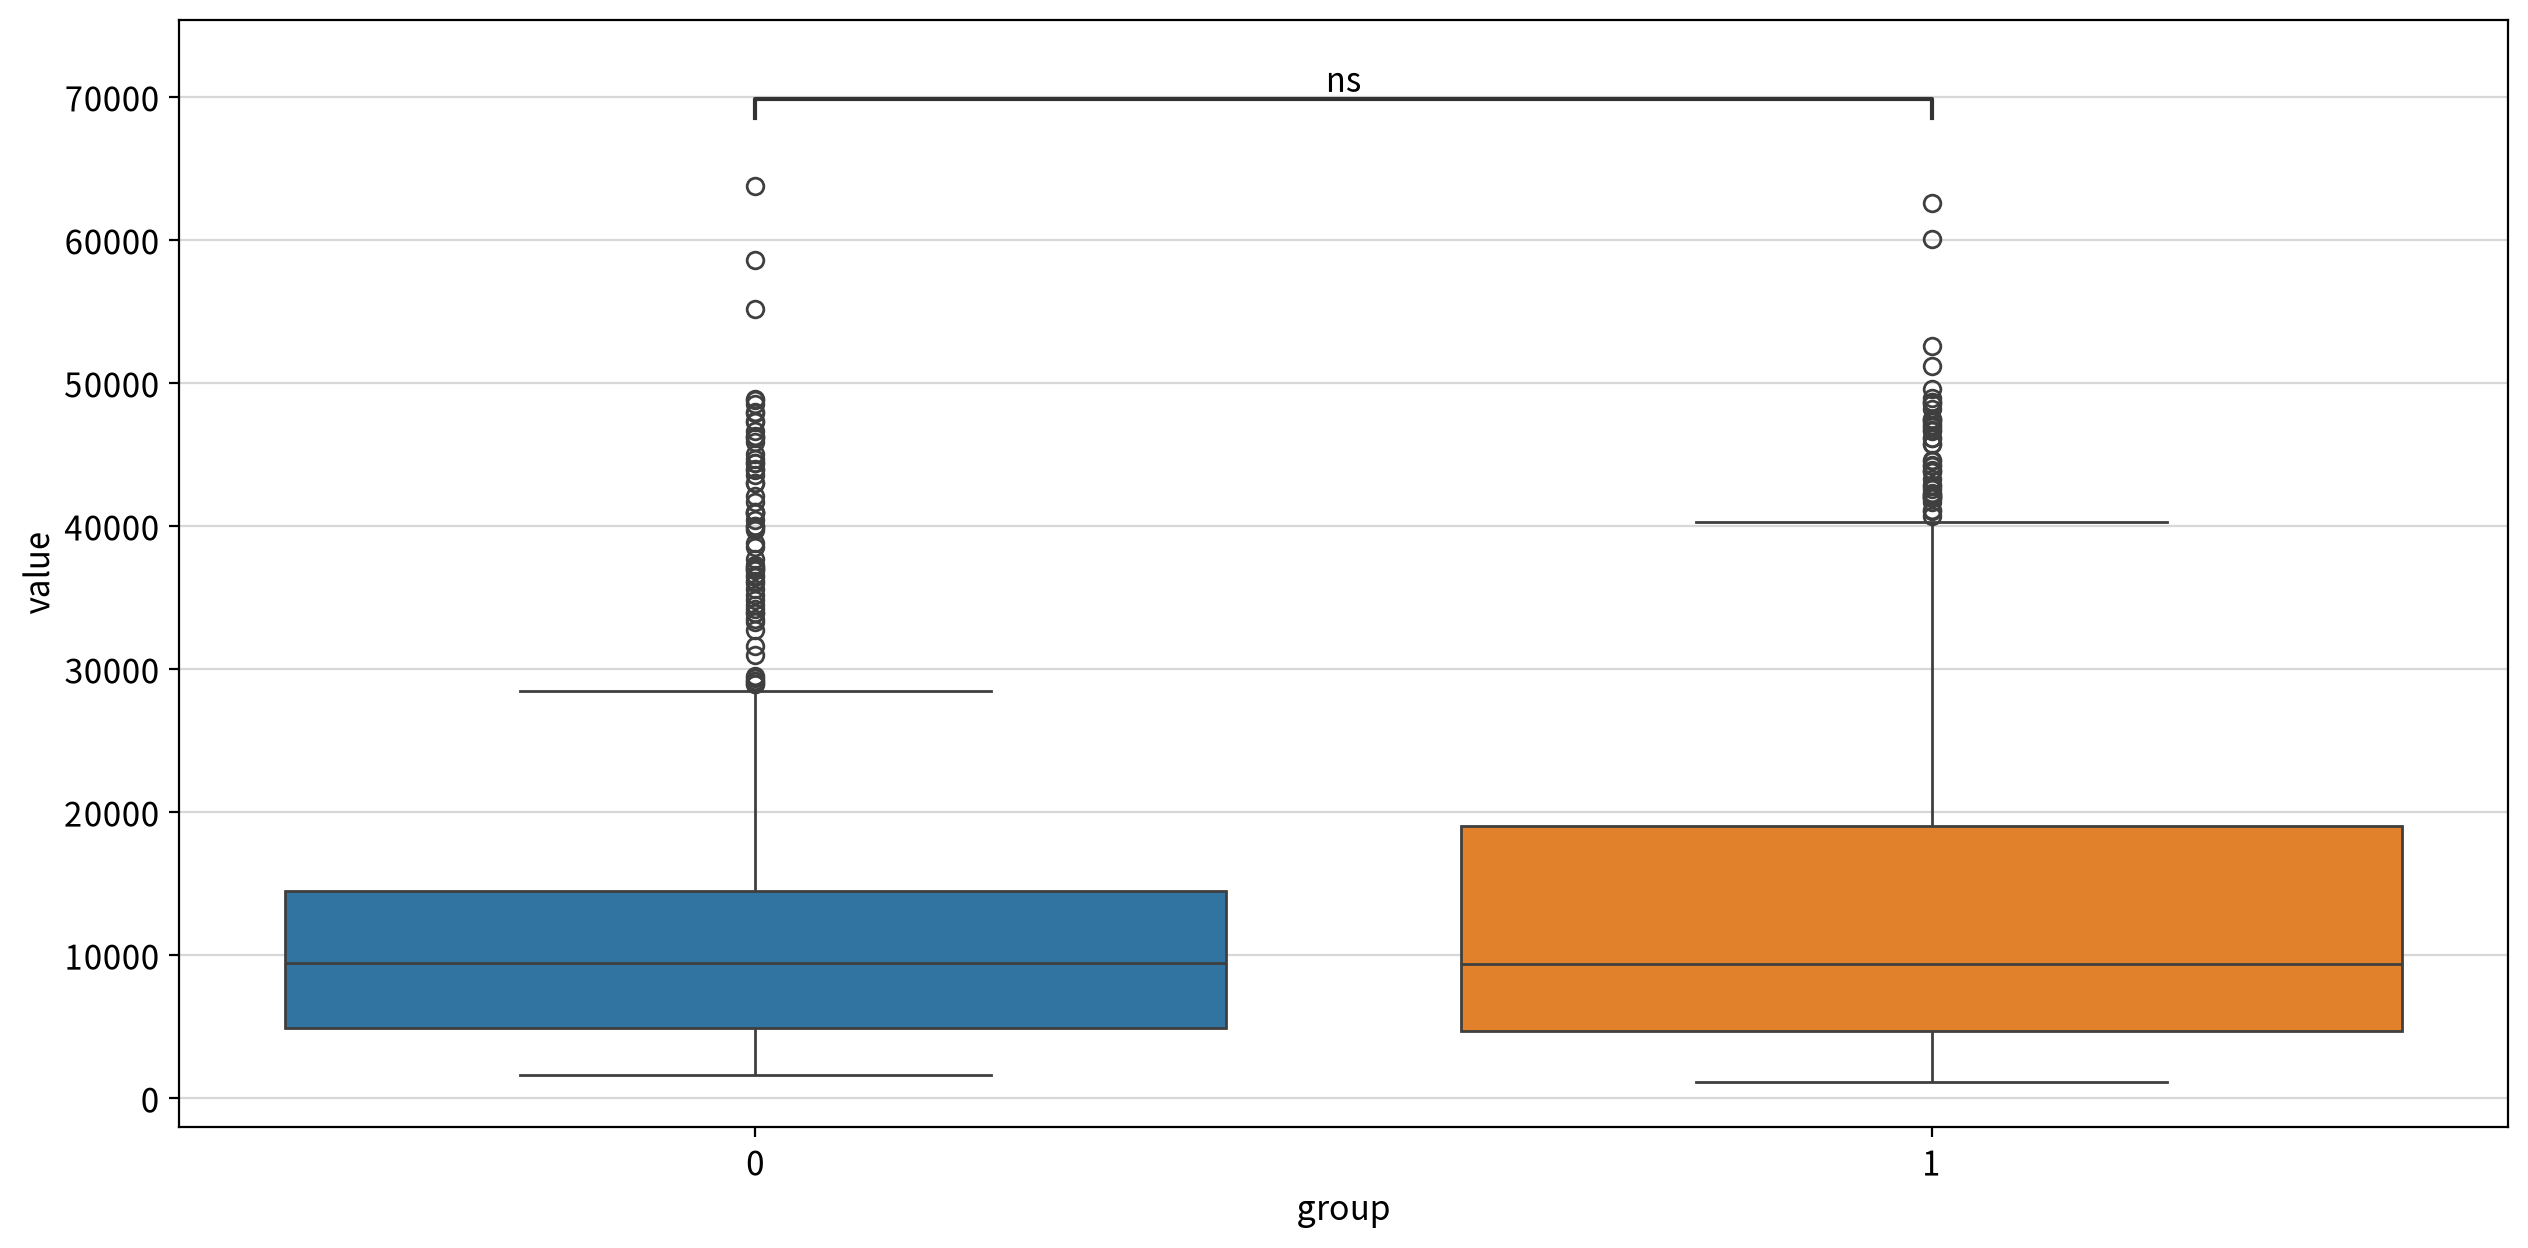

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided     220652.0   0.6945        False  0 = 1
                    less          220652.0   0.3472        False  0 ≥ 1
                    greater       220652.0   0.6528        False  0 ≤ 1

##### ▶︎ smoker(흡연 여부) → charges

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.747e-130 U_stat=7.403e+03


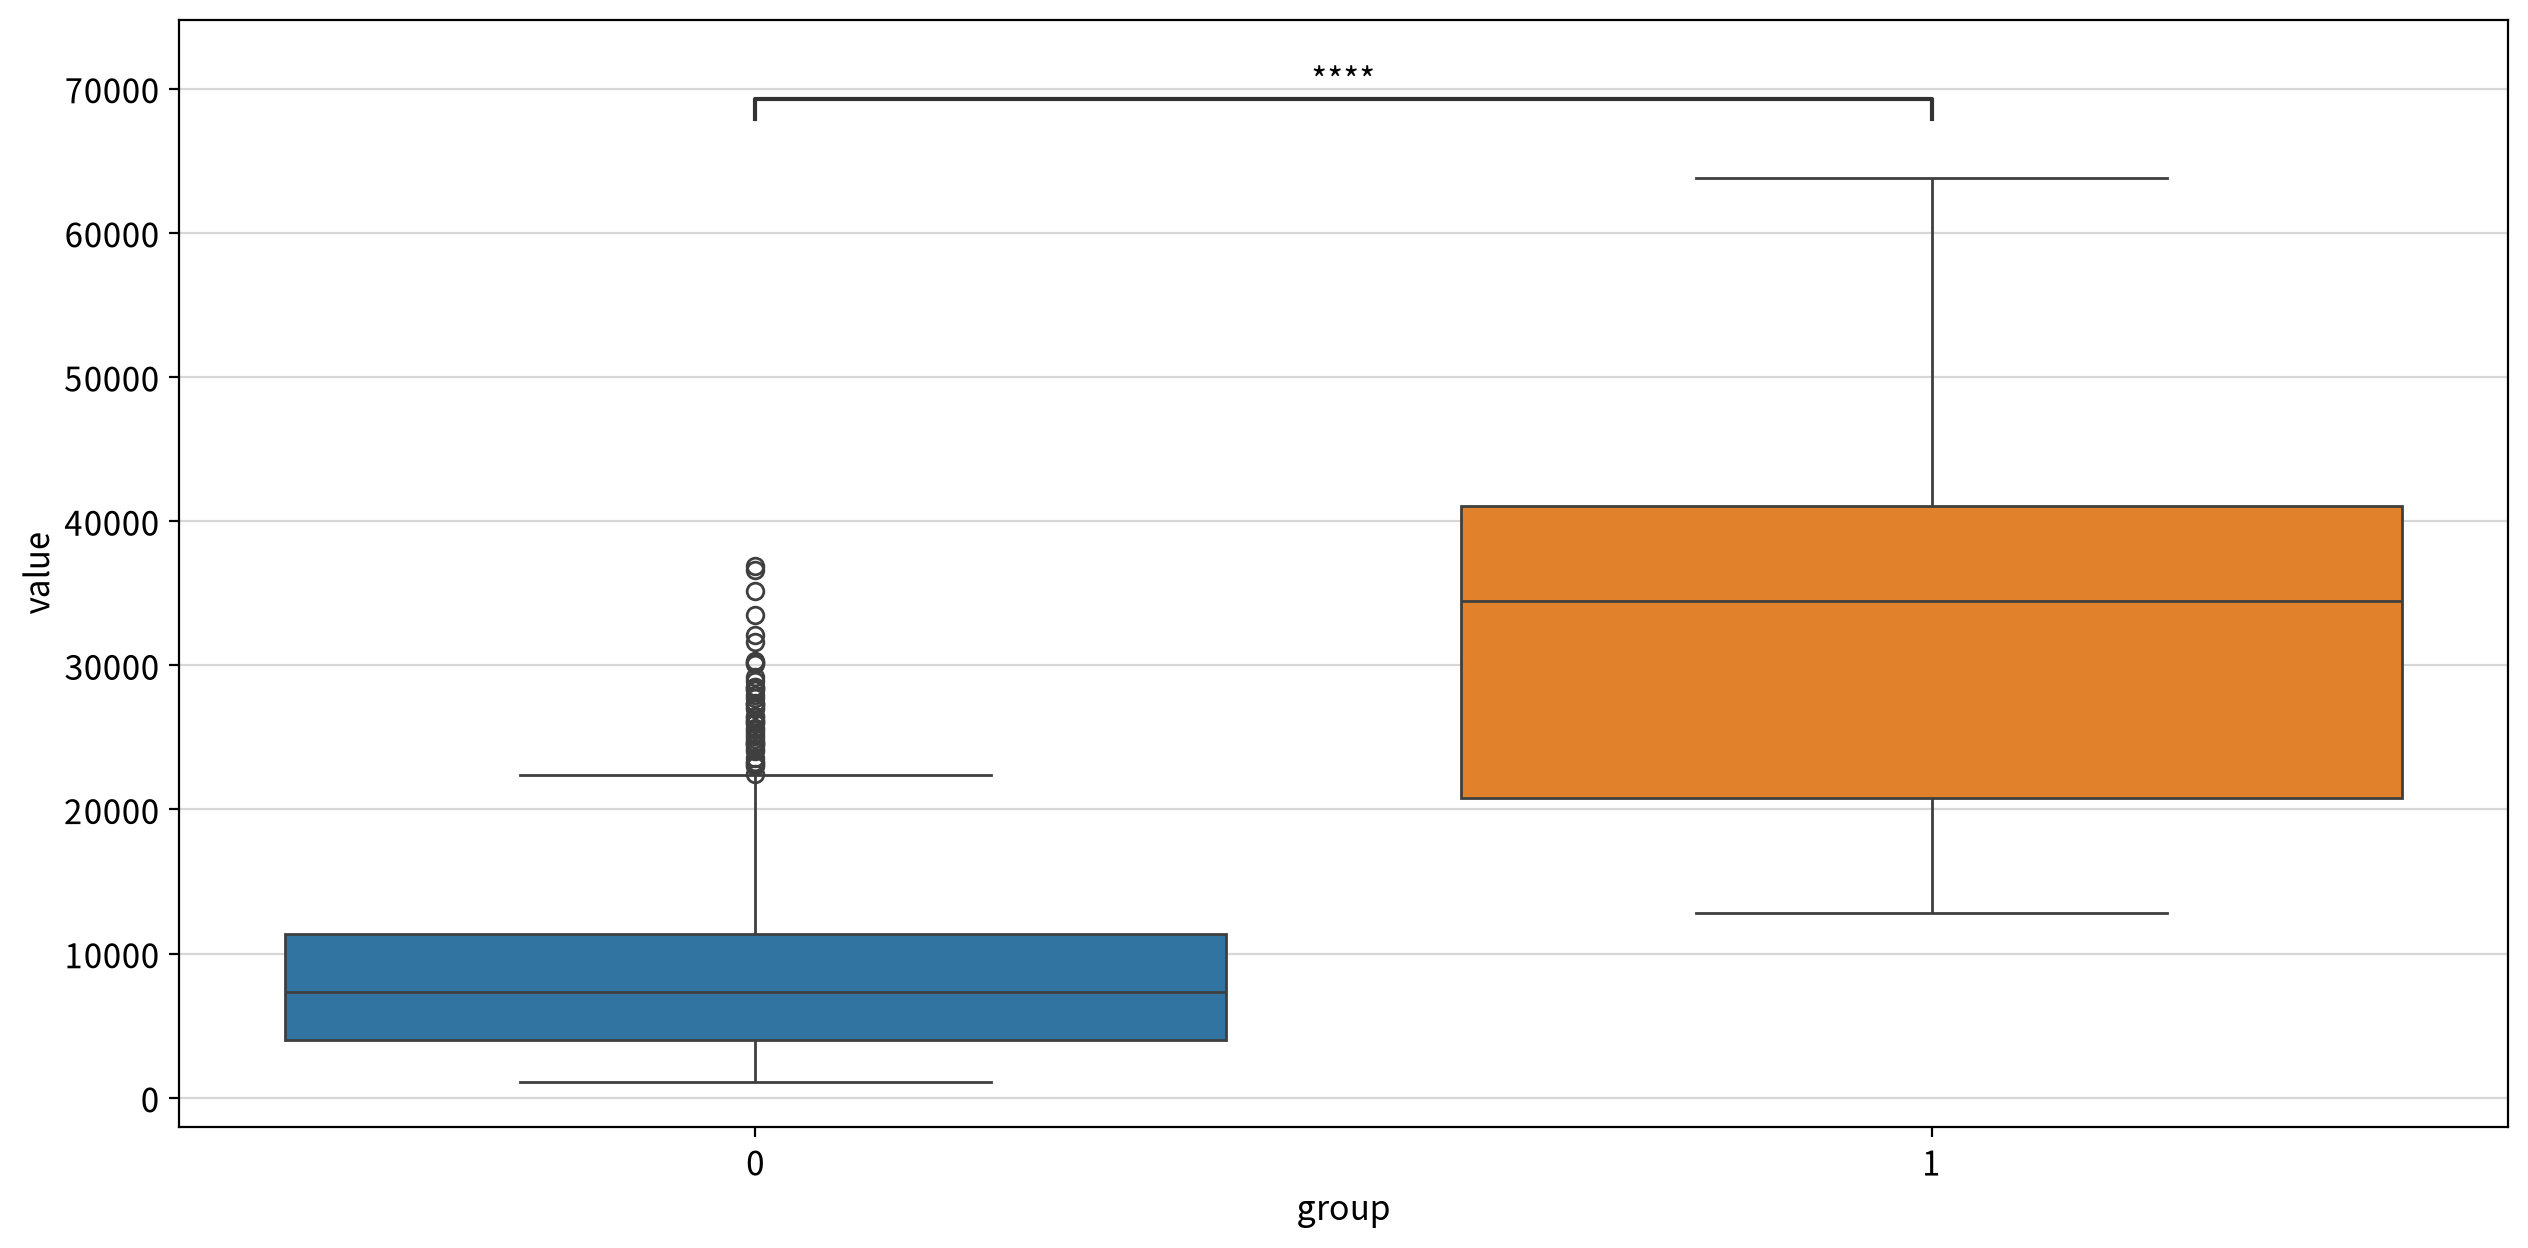

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided       7403.0      0.0         True  0 ≠ 1
                    less            7403.0      0.0         True  0 < 1
                    greater         7403.0      1.0        False  0 ≤ 1

In [21]:
for n in nominal_cols:
    ## 2개의 고유값만 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) == 2:
        ## 빈 줄 출력용
        print()

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        ## 수집된 데이터가 long 타입이므로 검정 대상만 wide 타입으로 변환해야 한다.
        wide_df = my_prep.long2wide(df, hue=n, values=target)
        display(my_stats.test_independent(wide_df,
                    group1=wide_df.columns[0], group2=wide_df.columns[1]))

**검정 결과**

| 변수 | 검정 | 통계량 | p-value | 판단 | 관련 가설 |
|---|---|---:|---:|---|---|
| `sex` | Mann-Whitney U | U = 220652.0 | **0.6945** (양측) | **차이 없음** (α = .05) | 성별에 따른 보험료 차이 없음 |
| `smoker` | Mann-Whitney U | U = 7403.0 | **< .001** (양측) | **차이 있음** (α = .05) | 흡연 여부에 따른 보험료 차이 있음 |

- **성별(`sex`)**에 따른 `charges` 차이는 통계적으로 유의하지 않았다(p = 0.6945). 남성과 여성의 보험료 분포에서 뚜렷한 차이가 있다고 보기 어렵다.
- **흡연 여부(`smoker`)**에 따른 `charges` 차이는 통계적으로 유의하였다(p < .001). 단측 검정에서도 `0 < 1`이 유의하게 나타나, **비흡연자보다 흡연자의 보험료가 높다.**
- `smoker`는 비흡연자 1,063명, 흡연자 274명으로 집단 크기 차이가 있으므로, 이후 다변량 모델에서 다른 변수들을 통제한 뒤에도 흡연 여부의 영향이 유지되는지 확인한다.

##### 3) ANOVA (x: 3집단 명목형 독립변수 → y: 종속변수)

- 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
  - 3개 이상의 고유값을 갖는 명목형이 없을 경우 출력 결과가 없을 수 있다.

In [22]:
for n in nominal_cols:
    ## 3개 이상의 고유값이 존재하는 명목형 독립변수에 대해서만 검정을 수행한다.
    if len(df[n].unique()) >= 3:
        print() ## 빈 줄 출력용

        ## 분석 단위 제목 출력
        display(Markdown(f"##### ▶︎ {n}({column_means[n]}) → {target}"))

        display(my_stats.anova_oneway(df, y=target, between=n))

        ## 사후검정
        display(my_stats.posthoc_oneway(df, y=target, between=n, plot=False))

##### ▶︎ region(미국 내 거주 지역) → charges

,test,Source,ddof1,ddof2,F,p_unc,np2,effect_size
0,welch_anova,region,3,740.41575,2.566223,0.053489,0.006542,Negligible


,test,A,B,mean_A,mean_B,diff,se,T,df,pval,hedges,significant,effet_size
0,Games-Howell,northeast,northwest,13406.384516,12450.840844,955.543672,877.192518,1.089320,645.827117,0.696208,0.085486,False,Negligible
1,Games-Howell,northeast,southeast,13406.384516,14735.411438,-1329.026921,962.947944,-1.380165,679.413390,0.512241,-0.104003,False,Negligible
2,Games-Howell,northeast,southwest,13406.384516,12346.937377,1059.447139,895.548855,1.183014,646.647993,0.637819,0.092763,False,Negligible
3,Games-Howell,northwest,southeast,12450.840844,14735.411438,-2284.570594,956.388659,-2.388747,677.136931,0.080191,-0.179842,False,Negligible
4,Games-Howell,northwest,southwest,12450.840844,12346.937377,103.903467,888.492137,0.116944,645.983103,0.999428,0.009170,False,Negligible
5,Games-Howell,southeast,southwest,14735.411438,12346.937377,2388.474060,973.252437,2.454116,683.096482,0.068257,0.185107,False,Negligible


**검정 결과**

| 변수 | 검정 | 통계량 | p-value | 효과크기 | 판단 | 관련 가설 |
|---|---|---:|---:|---|---|---|
| `region` | Welch ANOVA | F = 2.566 | **0.0535** | η² = 0.0065 (Negligible) | **차이 없음** (α = .05) | 지역에 따른 보험료 차이 없음 |

- **거주 지역(`region`)**에 따른 `charges`의 차이는 통계적으로 유의하지 않았다(p = 0.0535). 따라서 4개 지역의 평균 보험료에 유의한 차이가 있다고 보기 어렵다.
- 평균 보험료는 `southeast`가 약 **14,735달러**로 가장 높고 `southwest`가 약 **12,347달러**로 가장 낮았지만, 사후검정(Games-Howell)에서도 **모든 지역 간 비교가 유의하지 않았다.**
- 효과크기 역시 η² = **0.0065로 매우 작아, 지역이 보험료 차이를 설명하는 영향은 크지 않은 것으로 볼 수 있다.

다만 전체 검정의 p-value가 0.05에 근접한 0.0535이므로 지역별 차이의 경향은 확인되지만, 현재 유의수준에서는 통계적으로 유의하다고 판단하지 않는다.

#### 4-3. 다변량 분석 — 독립변수 간 상관

In [23]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
my_stats.correlation_summary(corr)

method    coef  p-value strength  significant  normality_x  \
x   y                                                                        
age bmi       Spearman  0.1079   0.0001     Weak         True        False   
    children  Spearman  0.0558   0.0413     Weak         True        False   
bmi children  Spearman  0.0156   0.5677     Weak        False        False   

              normality_y  linearity  influential  
x   y                                              
age bmi             False       True        False  
    children        False      False        False  
bmi children        False       True        False

,age,bmi,children
age,1.000,0.108,0.056
bmi,0.108,1.000,0.016
children,0.056,0.016,1.000


,max-y,max-coef,count,columns
x,,,,
age,bmi,0.1079,0,-
bmi,age,0.1079,0,-
children,age,0.0558,0,-


**해석**

- **Strong 구간(|ρ| ≥ 0.7)의 쌍:** 없음. `age`·`bmi`·`children` 간 상관계수는 모두 `0.108` 이하로, 전체적으로 **Weak 수준의 매우 약한 관계**를 보였다.
- **공통 구조:** 세 변수 사이에 뚜렷하게 함께 증가하거나 감소하는 구조는 나타나지 않았다. 즉, `age`·`bmi`·`children`은 서로 강하게 중복되는 정보를 가진 변수라고 보기 어렵다.
- **`age`–`bmi`는 통계적으로 유의한 약한 양의 상관관계**를 보였다(ρ = 0.1079, p = 0.0001). 다만 상관계수의 크기가 작아 실제 관계의 강도는 매우 약하다.
- **`age`–`children` 역시 통계적으로 유의한 약한 양의 상관관계**를 보였다(ρ = 0.0558, p = 0.0413). 그러나 상관계수가 0에 매우 가까워 관계의 크기는 미미하다.
- **`bmi`–`children`은 통계적으로 유의한 상관관계가 나타나지 않았다**(ρ = 0.0156, p = 0.5677). 따라서 두 변수 사이에 일정한 단조 관계가 있다고 보기 어렵다.
- **변수 간 중복 우려는 낮다.** 가장 높은 상관계수도 `age`–`bmi`의 0.1079에 불과하므로, 세 변수 사이에서 강한 다중공선성을 의심할 만한 관계는 확인되지 않았다.
- → 따라서 `age`, `bmi`, `children`은 **상관관계만을 근거로 제거할 필요가 없으며**, 이후 분석 및 모델링에서 각각의 설명변수로 유지할 수 있다.

#### 4-4. EDA 기반 가설 검토 및 모델링 계획

#### 4-4. EDA 기반 가설 검토 및 모델링 계획

**초기 가설 검토**

| 가설 | EDA 근거 | 모델링 계획 |
|---|---|---|
| H1. 흡연자는 비흡연자보다 의료비가 높을 것이다. | Mann–Whitney U 검정 결과 흡연자의 의료비가 유의하게 높았다(`U = 7,403`, `p < .001`). | **잠정 채택.** 나이와 BMI 등을 통제한 후에도 `smoker`의 효과가 유지되는지 회귀계수로 확인한다. |
| H2. 나이가 많을수록 의료비가 높아지며, 증가 폭은 일정하지 않을 수 있다. | `age`와 `charges`는 중간 정도의 양의 상관을 보였다(`ρ = +0.534`, `p < .001`). | 증가 방향은 확인되었다. 비선형성을 검증하기 위해 기본모형과 `age²`를 추가한 모형을 비교한다. |
| H3. BMI가 높을수록 의료비가 높아지는 경향은 흡연자에게서 더 뚜렷할 것이다. | 전체 자료에서 `bmi`와 `charges`의 상관은 유의하지만 약했다(`ρ = +0.120`, `p < .001`). 흡연 여부에 따른 기울기 차이는 아직 확인하지 않았다. | `bmi × smoker` 상호작용항을 추가하여 흡연 여부에 따라 BMI의 효과가 달라지는지 검증한다. |
| H4. 거주 지역에 따라 의료비 수준에 유의한 차이가 있을 것이다. | Welch ANOVA 결과 지역 차이가 유의하지 않았다(`F = 2.566`, `p = .0535`, `η² = .0065`). 사후검정에서도 유의한 지역 조합이 없었다. | **잠정 기각.** 다만 다른 변수를 통제한 회귀모형에서도 지역 더미변수가 유의하지 않은지 확인한다. |

**투입 변수 선정**

- 초기 설명변수는 `age`, `sex`, `bmi`, `children`, `smoker`, `region`을 모두 사용한다.
- `sex`와 `region`은 단변량 검정에서 유의하지 않았지만, 다른 변수를 통제한 결과를 확인하기 전에는 제외하지 않는다.
- 연속형 독립변수 사이의 가장 높은 상관도 `age`–`bmi`의 `ρ = 0.108`로 매우 낮아, 현재 단계에서 강한 변수 중복은 확인되지 않았다.
- 가설 검증을 위해 `age²`와 `bmi × smoker`를 파생항으로 추가한다.

**변수 변환 계획**

- `charges`는 왜도 `+1.52`의 우편향 분포이며 IQR 기준 상단 이상치가 139건이므로, 원자료 모형과 `log(charges)` 모형을 비교한다.
- `age`와 `bmi`는 분포의 비대칭성이 크지 않아 로그변환하지 않는다.
- `children`은 0~5명의 제한된 정수값을 갖는 이산형 변수이므로 원자료를 유지한다.
- `age²`와 `bmi × smoker`를 만들기 전에 `age`와 `bmi`를 평균 중심화하여 구성항과 파생항 사이의 불필요한 중복을 줄인다.
- `sex`, `smoker`, `region`은 더미변수로 변환하고 기준 범주를 명시한다.
- 관측 가능한 실제 값으로 판단된 `bmi` 및 `charges`의 이상치는 임의로 삭제하지 않는다.

**후보 모형**

| 모형 | 구성 | 확인 목적 |
|---|---|---|
| M1 | 기본 선형회귀 | 비교 기준선 |
| M2 | `log(charges)` | 의료비의 우편향 완화 |
| M3 | M2 + `age²` | 나이 효과의 비선형성 검증 |
| M4 | M2 + `bmi × smoker` | BMI 효과가 흡연 여부에 따라 달라지는지 검증 |
| M5 | M2 + `age²` + `bmi × smoker` | 두 가설을 함께 반영한 모형의 성능 확인 |

**평가지표와 최종 모형 선정 기준**

> **1순위 RMSE, 2순위 MAE, 3순위 R²와 모형의 간명성**

- 모든 모형은 동일한 학습자료와 평가자료를 사용한다.
- 로그모형의 예측값은 다시 달러 단위로 변환한 뒤 MAE·RMSE·R²를 계산한다.
- RMSE가 가장 낮은 모형을 우선하되, 성능 차이가 작다면 파생항이 적고 해석하기 쉬운 모형을 선택한다.
- 회귀계수와 p-value를 이용해 H1~H4를 최종 판정한다.
- 잔차 세부 진단, VIF, HC3 표준오차, 교차검증 및 다른 예측모형과의 비교는 후속 과제로 남긴다.